# FE 5108 — Portfolio choice, the CAPM, factor models, and the recommendation

This notebook is the **single reproducible entry point** for the project: run it
top to bottom (*Kernel ▸ Restart & Run All*) and it regenerates every exhibit
from the committed raw CSVs in `data/` — no network access needed.

All of the logic lives in the `goldman` package (`src/goldman/`); the notebook is
a thin, readable driver over the modules so you can see exactly what each step
does.

| Stage | Exhibits |
|---|---|
| 1 · Portfolio choice | (1a) summary statistics · (1b) tangency vs value weights · (1c) estimation error |
| 2 · The CAPM | (2a) β, α, t(α), R² · (2b) empirical SML · (2c) joint test of α = 0 · (2d) SML slope/intercept vs theory |
| 3 · Factors | (3a) factor construction · (3b) alphas before vs after factors · (3c) verdict |
| 4 · Judgment | (4a) Roll's critique · (4b) out-of-sample horse race · (4c) 60-year robustness · the recommendation |

**Setup.** `uv sync --extra notebook`, then open this file. The internet is only
needed to refresh data via `python -m goldman.data.fetch`; the committed CSVs are
enough to run the exhibits.

## Setup
Import the data and analysis modules and pick the output directory.

In [1]:
from goldman.analysis import (
    plot_weights,
    run_portfolio_analysis,
    subsample_tangency,
    summary_statistics,
    tangency_vs_comparison,
    weight_correlation,
)
from goldman.config import RF_MONTHLY, ensure_outputs_dir
from goldman.data import load_ff3, load_returns, load_value_weights, monthly_rf

UNIVERSE = "us"          # "us" or "sg"; "synthetic" is fake smoke-test data
OUTPUT_DIR = ensure_outputs_dir()
print("outputs ->", OUTPUT_DIR.name)

outputs -> outputs


## Load and clean the return panel

All cleaning decisions (sparse-ticker drops, fully-observed months) live once in
`goldman.data`, so this notebook and the tests see the same panel.

In [2]:
returns = load_returns(universe=UNIVERSE)
print(
    f"{returns.shape[1]} assets x {returns.shape[0]} months "
    f"({returns.index[0]:%Y-%m} .. {returns.index[-1]:%Y-%m})"
)
returns.iloc[:3, :5].round(4)

30 assets x 119 months (2016-10 .. 2026-08)


,AAPL,AMZN,BAC,CSCO,CVX
Date,,,,,
2016-10-01,0.0043,-0.0567,0.0543,-0.0248,0.0178
2016-11-01,-0.0216,-0.0497,0.2847,-0.0280,0.0757
2016-12-01,0.0480,-0.0009,0.0464,0.0134,0.0550


## Risk-free rate and factor data

We use the monthly risk-free rate from the bundled Fama–French file, which is
aligned to our calendar by `monthly_rf` (falling back to a constant outside its
coverage). This is the same input the CAPM and factor stages will use later.

In [3]:
rf = monthly_rf(returns.index, ff3=load_ff3(), fallback=RF_MONTHLY)
rf.describe()

count    119.000000
mean       0.001944
std        0.001578
min        0.000000
25%        0.000350
50%        0.001800
75%        0.003400
max        0.004800
Name: RF, dtype: float64

## Point-in-time value weights

`load_value_weights` reads the long-format CSV built from per-ticker prices and
shares outstanding, aligns it to this return panel (forward-fill, so no month
ever uses a future share count) and renormalises each date. The benchmark is
therefore a genuine value-weighted index, not today's market caps applied to
old data.

In [4]:
value_weights = load_value_weights(
    universe=UNIVERSE, assets=returns.columns, dates=returns.index
)
print(f"{value_weights.shape[1]} assets x {value_weights.shape[0]} months")
value_weights.mean().sort_values(ascending=False).head(10).round(4)

30 assets x 119 months


asset
AAPL     0.1523
MSFT     0.1365
GOOGL    0.1096
AMZN     0.1014
NVDA     0.0619
META     0.0598
JPM      0.0375
JNJ      0.0350
WMT      0.0335
XOM      0.0315
dtype: float64

## (1a) Summary statistics
Annualised mean, volatility and Sharpe, plus monthly extremes.

In [5]:
summary = summary_statistics(returns, rf=rf)
summary.to_csv(OUTPUT_DIR / "summary_stats.csv")
print("wrote", "outputs/summary_stats.csv")
summary

wrote outputs/summary_stats.csv


,mean (ann.),vol (ann.),sharpe (ann.),min month,max month
AAPL,0.292,0.272,0.983,-0.181,0.217
AMZN,0.233,0.312,0.671,-0.238,0.273
BAC,0.202,0.286,0.625,-0.250,0.285
CSCO,0.186,0.249,0.655,-0.155,0.316
CVX,0.153,0.285,0.453,-0.224,0.273
DIS,0.068,0.306,0.146,-0.186,0.249
GOOGL,0.253,0.270,0.852,-0.179,0.338
HD,0.145,0.229,0.529,-0.151,0.189
INTC,0.224,0.532,0.378,-0.354,1.141
JNJ,0.124,0.173,0.584,-0.122,0.144


## (1b) Tangency weights vs value weights

The estimated tangency portfolio is `w_F ∝ Σ̂⁻¹ μ̂_e`; the comparison is the
value-weighted index. The chart uses the sample-average value-weight vector (the
full monthly panel is written out by `run_portfolio_analysis` below).

In [6]:
comparison_label = "value weights (sample average)"
weight_table = tangency_vs_comparison(returns, rf=rf, comparison=value_weights)
print(f"most extreme tangency weight: {weight_table['tangency'].abs().max():+.0%}")
weight_table.head()

most extreme tangency weight: +272%


,tangency,comparison
AAPL,0.430224,0.152336
AMZN,0.395464,0.101441
BAC,-0.462826,0.025369
CSCO,0.291083,0.018440
CVX,0.550929,0.021576


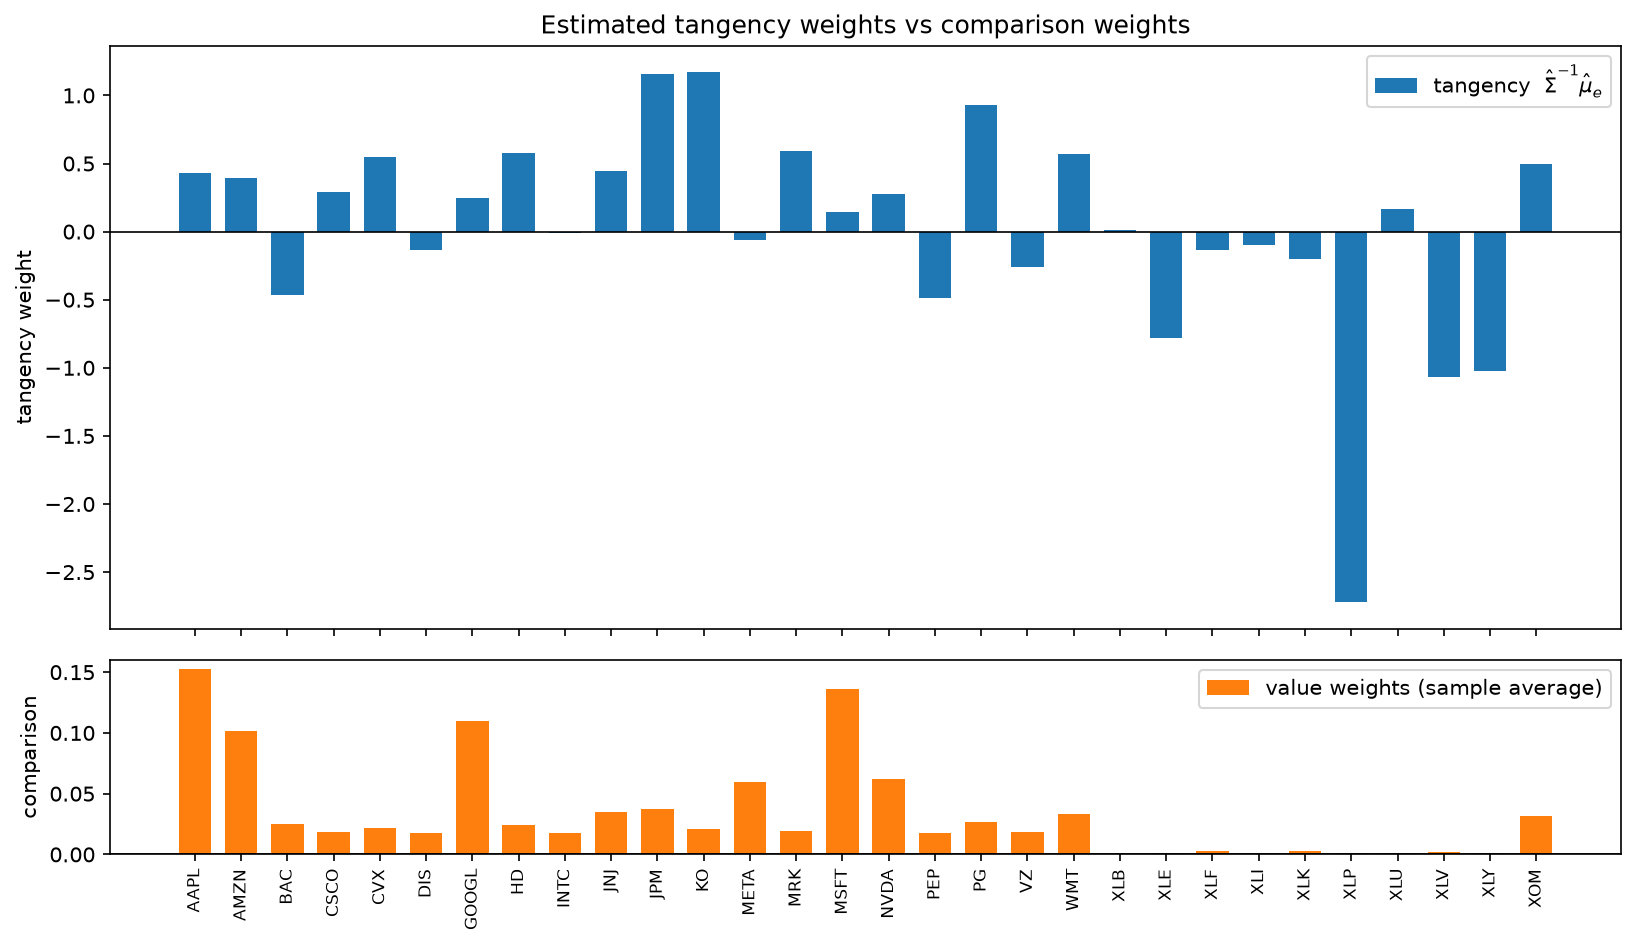

wrote outputs/tangency_weights.png


In [7]:
from IPython.display import Image, display

plot_weights(
    weight_table,
    OUTPUT_DIR / "tangency_weights.png",
    comparison_label=comparison_label,
)
display(Image(filename=OUTPUT_DIR / "tangency_weights.png"))
print("wrote", "outputs/tangency_weights.png")

**Takeaway (1b).** The tangency portfolio takes large long–short positions
(hundreds of percent in a single name, dwarfing the ≤16% value weights) while
the value benchmark holds small, positive weights. The two disagree because the tangency weights invert a noisy `Σ̂` and
amplify noisy `μ̂` — the Monte-Carlo of estimation error, not a real signal.

## (1c) Estimation error: subsample re-estimation
Re-estimate on each half of the sample and see how far the weights move.

In [8]:
drift = subsample_tangency(returns, rf=rf).round(3)
drift.to_csv(OUTPUT_DIR / "subsample_weights.csv")
corr = weight_correlation(drift, "first half", "second half")
print(f"correlation between first- and second-half weight vectors: {corr:.2f}")
drift.head()

correlation between first- and second-half weight vectors: 0.35


,first half,second half,full sample
AAPL,0.124,1.238,0.430
AMZN,-0.040,0.108,0.395
BAC,-0.108,-2.786,-0.463
CSCO,0.284,0.483,0.291
CVX,0.572,-0.074,0.551


**Takeaway (1c).** A low correlation between the two half-sample weight
vectors (printed above) says the estimates are unstable: the same theory,
the same assets, a different window — very different portfolios. This is why
naive mean–variance is hard to deploy and why shrinkage or constraints help.

### (1c, continued) Taming the weights: a no-short constraint and shrinkage

The handout's FAQ asks to *show how a no-short constraint or shrinkage tames*
the extreme weights. Four versions of the tangency portfolio, each estimated on
the full sample and on each half:

* **plug-in** — sample `μ̂` and `Σ̂` (the portfolio above);
* **long-only** — the same inputs, no short sales (a constraint acts as shrinkage
  of `Σ̂`; Jagannathan and Ma 2003);
* **shrinkage** — Ledoit–Wolf (2004) covariance, and means shrunk toward the
  CAPM prior `π = β × market premium` by a James–Stein weight that the data
  choose (full shrinkage would give exactly the value-weighted portfolio);
* **shrinkage, long-only** — both.

The CAPM prior's market premium is the historical US equity premium known when
the sample starts (Ken French market, July 1926 – September 2016).

prior market premium: 7.8% p.a. (US, 1926-07 .. 2016-09)

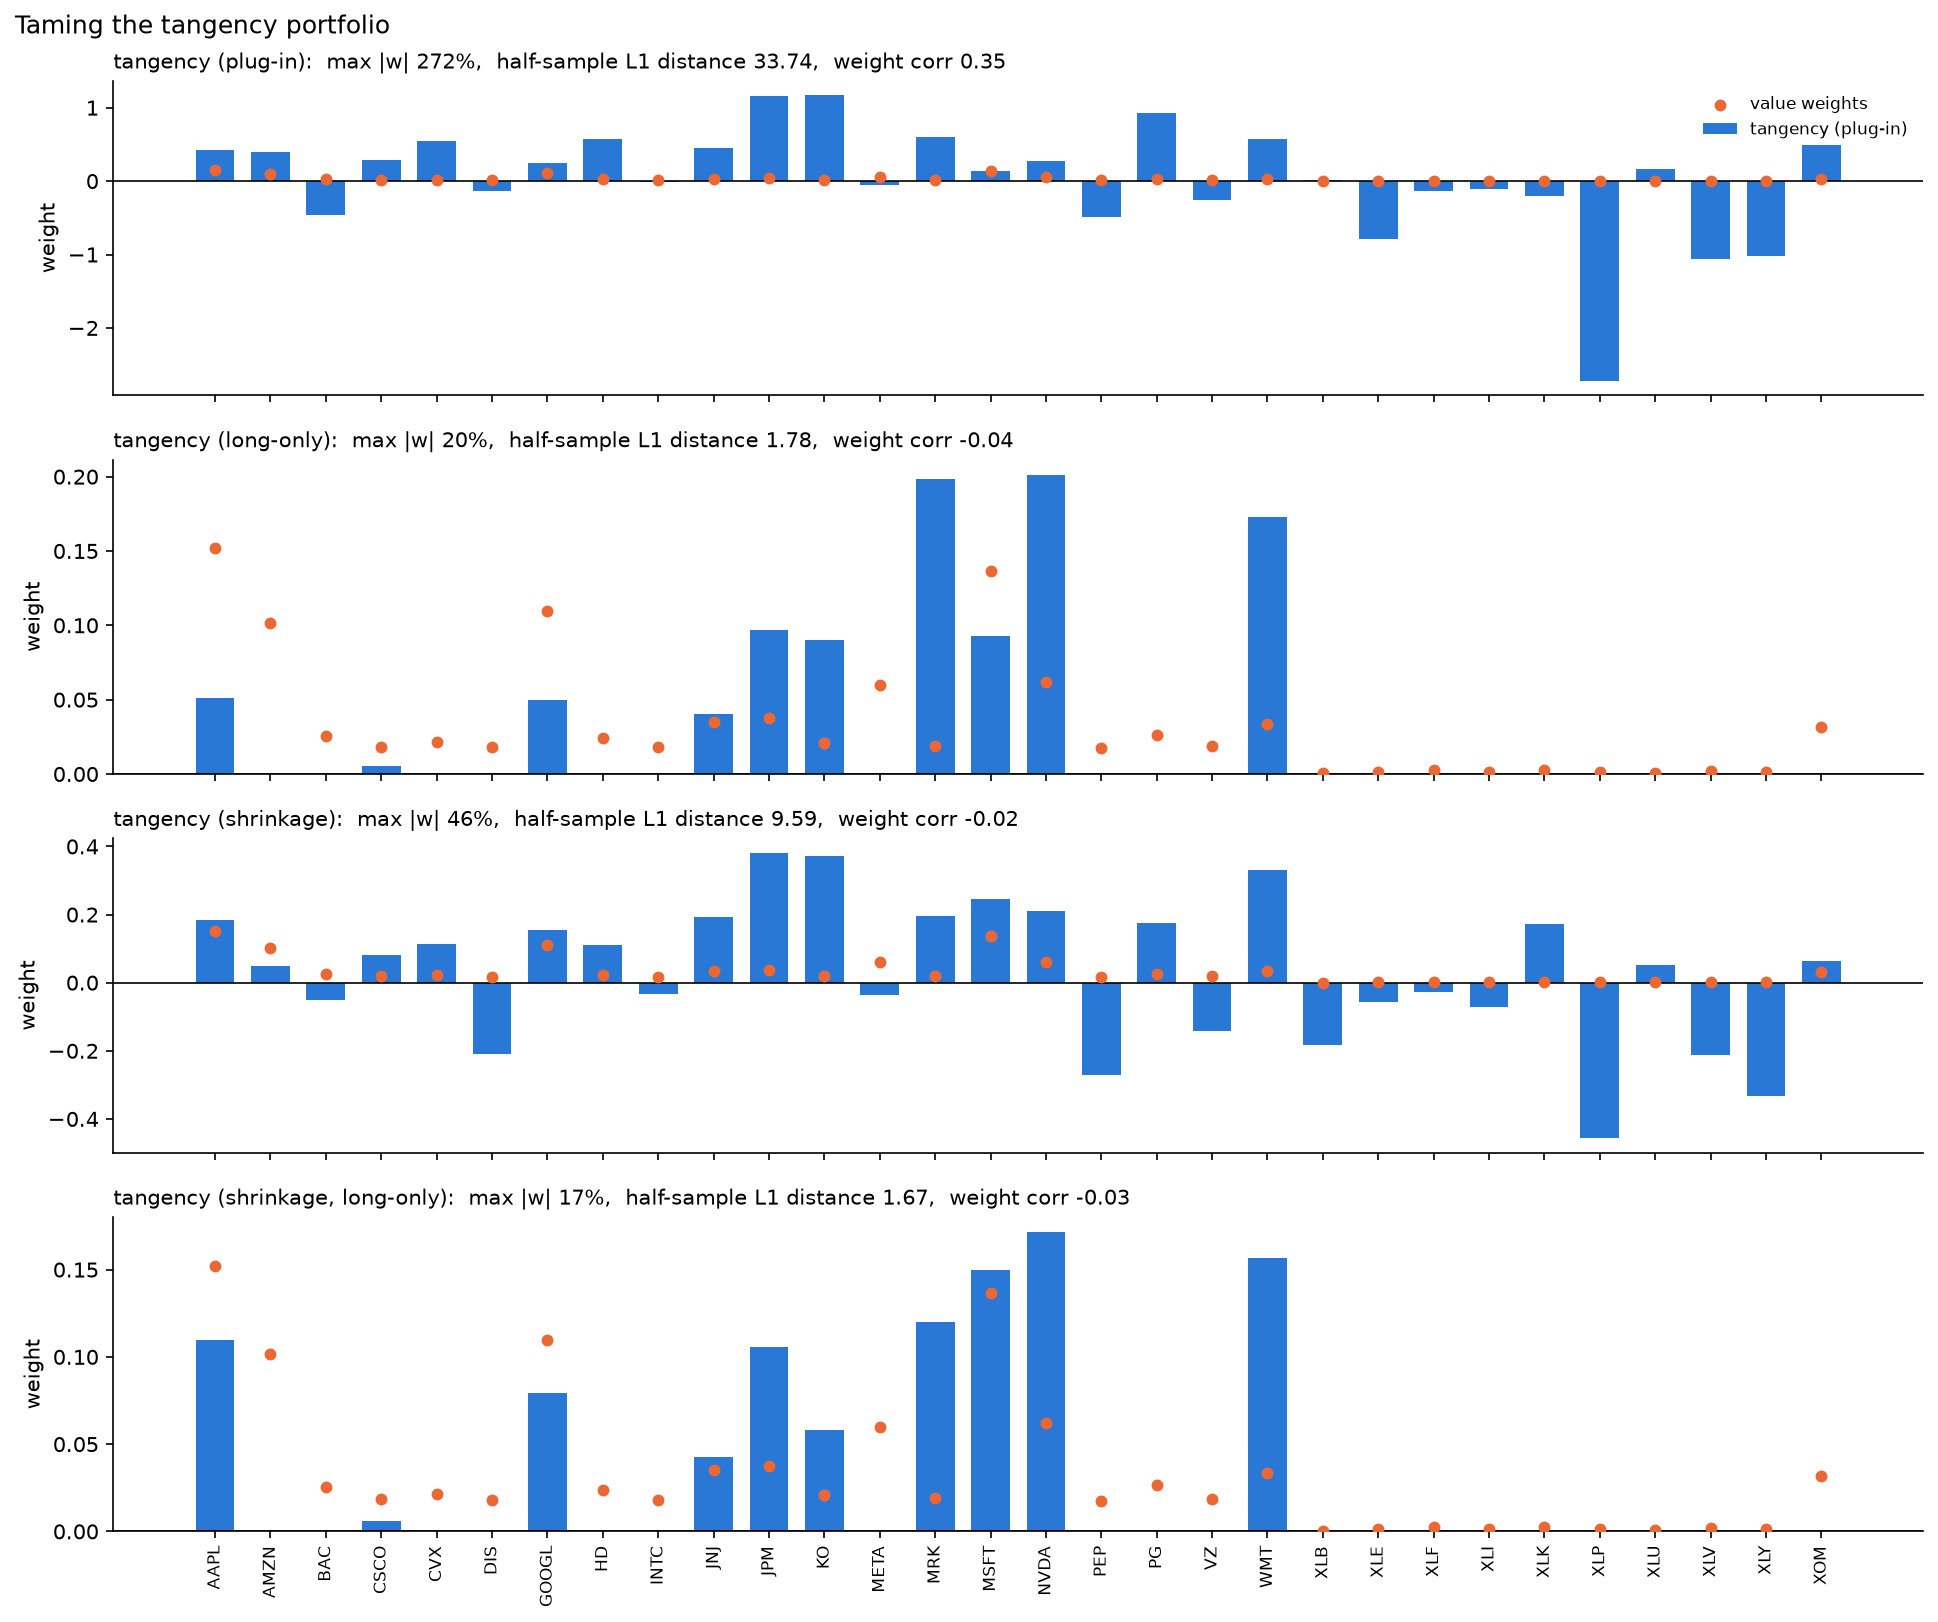

,max |weight|,gross exposure,short positions,half-sample weight corr,half-sample L1 distance,in-sample sharpe (ann.),weight on CAPM prior
portfolio,,,,,,,
tangency (plug-in),2.723,15.883,13.0,0.354,33.737,2.393,0.000
tangency (long-only),0.201,1.000,0.0,-0.043,1.779,1.539,0.000
tangency (shrinkage),0.457,5.167,13.0,-0.023,9.586,2.040,0.539
"tangency (shrinkage, long-only)",0.171,1.000,0.0,-0.033,1.672,1.516,0.539
value weights,0.152,1.000,0.0,NaN,NaN,1.230,1.000


In [9]:
import pandas as pd

from goldman.analysis import plot_taming, taming_comparison
from goldman.data import load_long_history

history = load_long_history()  # Ken French files back to 1926
start = pd.Period(returns.index[0], "M")
prior_premium = history.factors_full["Mkt-RF"].loc[: start - 1].mean()
print(f"prior market premium: {prior_premium * 12:.1%} p.a. (US, 1926-07 .. {start - 1})")

taming = taming_comparison(returns.sub(rf, axis=0), value_weights.mean(), prior_premium)
taming.table.to_csv(OUTPUT_DIR / "taming_table.csv")
plot_taming(taming, OUTPUT_DIR / "taming_weights.png")
display(Image(filename=OUTPUT_DIR / "taming_weights.png"))
taming.table.round(3)

**Takeaway (1c, taming).** Both cures shrink the positions dramatically: the largest
weight falls from 272% (plug-in) to 20% (long-only), 46% (shrinkage) and 17% (both);
gross exposure from 15.9× capital to 1–5×; and the distance between the
first-half and second-half portfolios — the turnover needed to move from one to
the other — from 34× capital to under 2× for the long-only versions. The data put
a 54% weight on the CAPM prior. But the tamed weights are still **uncorrelated
across the two halves** (correlation −0.04 to −0.02): taming limits the damage
estimation error can do; it cannot create information that is not in `μ̂`. The
in-sample Sharpe ratios (2.4 plug-in vs 1.2 for the value weights) are no guide
either — the plug-in portfolio maximises in-sample Sharpe *by construction*.
Whether any of these portfolios is worth holding is an out-of-sample question,
answered in Stage 4.

### (1c, appendix) Is it the ETFs?

Nine of our assets are sector ETFs that *hold* the other assets, so some return
columns are nearly linear combinations of others. That makes `Σ̂` ill-conditioned,
and its inverse turns small differences in `μ̂` into offsetting long–short bets
(above: short XLP, long KO, PG and PEP). Does the extreme portfolio survive without
the overlap?

In [10]:
from goldman.analysis import subset_tangency_check

etfs = [c for c in returns.columns if c.startswith("XL")]
stocks = [c for c in returns.columns if c not in etfs]
overlap = subset_tangency_check(
    returns.sub(rf, axis=0),
    {"30 assets": list(returns.columns), "21 stocks": stocks, "9 sector ETFs": etfs},
)
overlap.to_csv(OUTPUT_DIR / "tangency_by_subset.csv")
overlap.round(2)

,assets,condition number (corr),max |weight|,gross exposure,short positions,half-sample weight corr,half-sample L1 distance
universe,,,,,,,
30 assets,30.0,490.22,2.72,15.88,13.0,0.35,33.74
21 stocks,21.0,93.87,0.79,4.51,6.0,0.14,9.88
9 sector ETFs,9.0,54.40,1.11,3.76,4.0,-0.02,7.30


**Takeaway (1c, appendix).** Partly. Dropping the ETFs cuts the condition
number of the correlation matrix from 490 to 94, the largest position from 272%
to 79% and gross exposure from 15.9× to 4.5×: the overlap explains the most
extreme hedges. But the 21-stock tangency portfolio still runs 4.5× gross with six
shorts, and its two half-sample estimates are nearly unrelated (correlation 0.14).
The overlap amplifies estimation error; it does not cause it, so the conclusion of
(1c) stands.

## One-call reproduction

`run_portfolio_analysis` runs all of the above and writes every exhibit,
including the full monthly value-weight panel (`value_weights.csv`).

In [11]:
result = run_portfolio_analysis(
    returns,
    rf=rf,
    comparison=value_weights,
    comparison_label=comparison_label,
    output_dir=OUTPUT_DIR,
)
for name, path in result.output_paths.items():
    print(f"{name:14s} outputs/{path.name}")

summary        outputs/summary_stats.csv
weights        outputs/tangency_weights.png
subsample      outputs/subsample_weights.csv
value_weights  outputs/value_weights.csv


---
# Stage 2 · The CAPM

For every asset we run the security characteristic regression

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(R_{M,t} - R_{f,t}) + \varepsilon_{i,t}$$

**Proxies (state once in the report).**

* **Market proxy:** the Ken French `Mkt-RF` — the value-weighted return on all
  CRSP common stocks listed on NYSE, AMEX and NASDAQ, minus the T-bill rate. It
  is the broadest available US equity portfolio, it is value-weighted as the
  CAPM's market portfolio is, and it comes from the same source as the Stage 3
  factors, so the stages are consistent. (Roll's critique — Stage 4 — asks how
  much the answers change with a different proxy; `run_capm_analysis` takes the
  proxy as an argument for exactly that.)
* **Risk-free rate:** the one-month US T-bill from the same file.

Stages 2–3 use **US** Ken French data, so they are only valid for `UNIVERSE = "us"`.
A Singapore run needs a local market proxy (e.g. the STI) and an SGD rate
(MAS bills / SORA) — and self-built factors for Stage 3.

In [12]:
import pandas as pd

from goldman.analysis import (
    factor_summary,
    run_capm_analysis,
    run_factor_analysis,
    sml_comparison,
    standard_models,
)
from goldman.data import align_excess_returns, load_factors, load_ff5, load_test_portfolios

assert UNIVERSE == "us", "Stages 2-3 use US Ken French factors; see the note above."

factors = load_factors()  # Mkt-RF, SMB, HML, RF (FF3) + Mom
excess, fac = align_excess_returns(returns, factors)
market = fac["Mkt-RF"]
print(
    f"{excess.shape[1]} assets x {len(excess)} months "
    f"({excess.index[0]} .. {excess.index[-1]}); "
    f"market premium {market.mean() * 12:.1%} p.a., "
    f"risk-free {fac['RF'].mean() * 12:.2%} p.a."
)

30 assets x 119 months (2016-10 .. 2026-08); market premium 13.3% p.a., risk-free 2.33% p.a.


## (2a) Betas, alphas, t-statistics and R²

`t(alpha)` uses the usual OLS standard errors; `t(alpha) NW` uses Newey–West
(heteroskedasticity- and autocorrelation-robust, 4 lags) as a check that the
inference does not hinge on the error assumptions. Alphas are annualised
(monthly × 12).

In [13]:
capm = run_capm_analysis(
    excess, market, output_dir=OUTPUT_DIR, title="Empirical SML — 30 US assets"
)
capm.table.sort_values("t(alpha)", ascending=False).round(3)

,beta,t(beta),alpha (ann.),t(alpha),t(alpha) NW,R2,resid vol (ann.)
asset,,,,,,,
NVDA,1.750,8.106,0.352,2.877,2.467,0.360,0.375
MSFT,0.906,8.835,0.116,1.990,1.904,0.400,0.178
XLK,1.144,19.087,0.066,1.940,2.186,0.757,0.104
AAPL,1.102,9.138,0.122,1.788,2.036,0.416,0.209
WMT,0.494,4.878,0.096,1.677,1.863,0.169,0.176
GOOGL,1.065,8.795,0.089,1.293,1.444,0.398,0.210
MRK,0.261,2.143,0.087,1.260,1.190,0.038,0.211
JPM,1.070,10.756,0.061,1.085,1.164,0.497,0.173
JNJ,0.422,4.575,0.045,0.863,0.929,0.152,0.160


**Takeaway (2a).** Betas line up with economic intuition — defensive staples,
pharma and telecom (KO, PG, PEP, MRK, VZ) sit between 0.26 and 0.43, banks and
tech near or above 1, NVDA highest at 1.75 — and are estimated precisely (every t(β) > 2).
Alphas are a different matter: they are economically large (NVDA +35% p.a.,
MSFT/AAPL +12%, DIS −13%) but statistically weak — only NVDA has |t| > 2 with
OLS errors. R² is generally higher for the diversified sector ETFs (up to 0.81
for XLY) than for single stocks (as low as 0.04 for MRK): most single-stock risk is
idiosyncratic, which is why individual alphas are so hard to pin down.

## (2b) The empirical security market line

Average excess return against estimated beta. The **theoretical SML** passes
through the origin with slope equal to the average market excess return; the
**fitted SML** is the Fama–MacBeth cross-sectional fit.

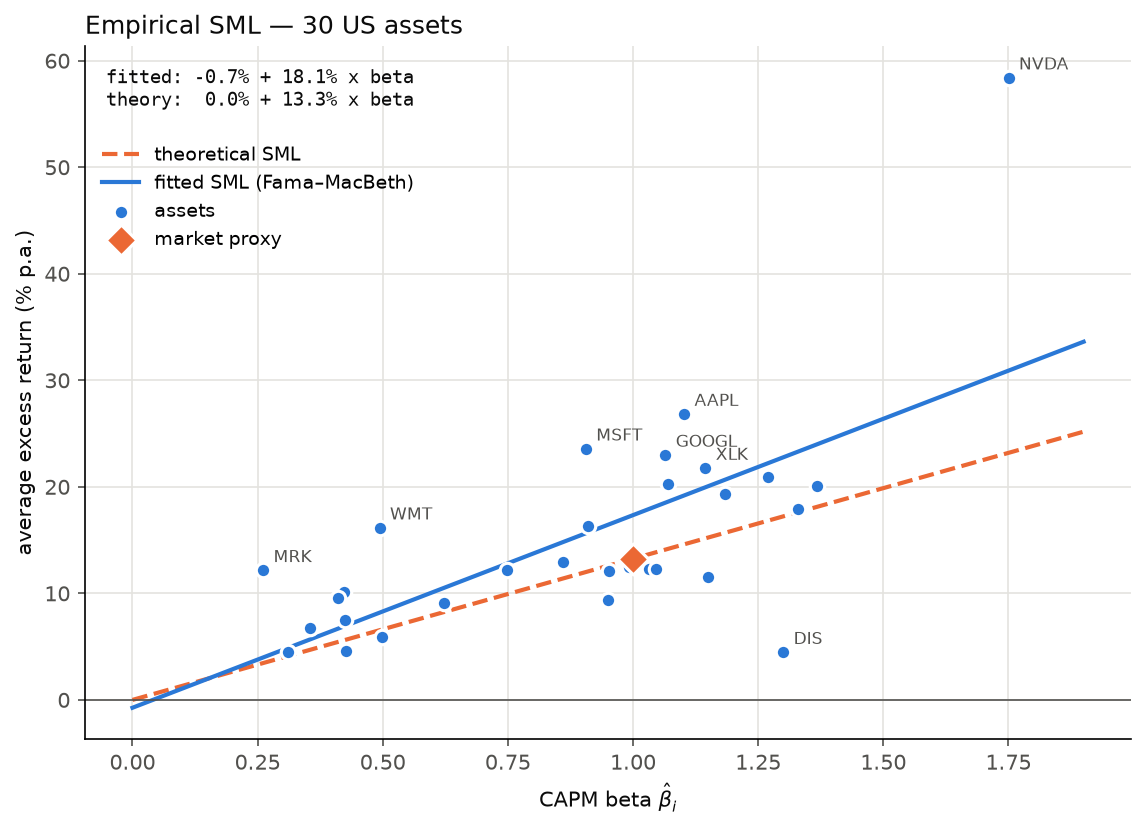

In [14]:
from IPython.display import Image, display

display(Image(filename=capm.output_paths["sml"]))

**Takeaway (2b).** In our universe the fitted SML is *steeper* than theory and
passes close to the origin — but the picture is dominated by one point: NVDA
(β = 1.75, 58% p.a. excess return). Most assets scatter around the theoretical
line with no visible relation between beta and average return beyond it. (2d)
tests whether this steepness is real.

## (2c) Are all alphas jointly zero?

Two answers. **(i) Counting:** with 30 assets and a 5% test, chance alone gives
about 30 × 0.048 ≈ 1.4 alphas with |t| > 2. **(ii) GRS (Gibbons, Ross and Shanken
1989):** a single F-test of α₁ = … = α_N = 0 that accounts for the correlation of
residuals across assets — the formal version of the count.

In [15]:
capm.joint_test

GRS statistic                                 1.247197
GRS p-value                                   0.212634
GRS df                                       F(30, 88)
n tests                                             30
observed |t|>2                                       1
P(|t|>2) per test                             0.047817
expected by chance                              1.4345
P(at least observed)                          0.770058
Bonferroni p (largest |t|)                    0.143104
observed |t|>2 (NW)                                  4
mean |alpha| (ann.)                           0.052073
min detectable alpha (ann., median asset)      0.16173
avg residual correlation                      0.031905
avg |residual correlation|                    0.213684
Name: joint test, dtype: object

**Takeaway (2c).** We **cannot reject** that all 30 alphas are zero: GRS = 1.25,
p = 0.21. One |t| > 2 versus 1.4 expected by chance (probability of at least one
≈ 0.77); even NVDA's t = 2.88 is not significant after a Bonferroni correction
for 30 tests (p ≈ 0.14). With Newey–West errors four alphas cross |t| = 2
(NVDA, XLK, AAPL, DIS) — borderline: if the 30 tests were independent,
P(at least 4) ≈ 0.05. They are not independent: three of the four are tech
exposures with correlated residuals (XLK holds AAPL and NVDA; residual
correlations with XLK ≈ 0.45), so they are closer to one finding than three.
The average pairwise residual correlation is only 0.03 because sector pairs
cancel (XLF–XLK −0.66, XLE–XOM +0.93); the mean absolute correlation is 0.21.
GRS accounts for this correlation but assumes serially uncorrelated,
homoskedastic errors — the Newey–West count is the check on that assumption,
and it does not overturn the verdict. Caveat on power: ten years
of monthly data cannot detect alphas of a few percent a year — the NVDA estimate
of +35% p.a. has a standard error of about 12% p.a., and for the median asset the
smallest alpha a 5% test would detect with 80% power is about **16% p.a.**
(`min detectable alpha` above).

In [16]:
from goldman.analysis import alpha_joint_test, capm_regressions

stocks_only = alpha_joint_test(capm_regressions(excess[stocks], market))
stocks_only.to_csv(OUTPUT_DIR / "alpha_joint_test_stocks.csv")
stocks_only[["GRS statistic", "GRS p-value", "GRS df", "observed |t|>2", "expected by chance"]]

GRS statistic          1.583306
GRS p-value             0.06927
GRS df                F(21, 97)
observed |t|>2                1
expected by chance      1.00415
Name: joint test, dtype: object

**Robustness (2c), 21 stocks only.** Without the ETFs, GRS = 1.58 with
p = 0.07: the 21 stock alphas are jointly significant at 10% but not at 5%, with
one |t| > 2 against 1.0 expected. The ETFs, whose alphas are small and precisely
estimated, dilute the joint test. Together with the power calculation, the honest
verdict is *weak evidence against the CAPM, not enough to reject it*.

## (2d) The fitted SML versus theory

Theory says intercept = 0 and slope = average market excess return. The
Fama–MacBeth standard errors are robust to cross-sectional correlation; the
Shanken column also corrects for the betas being estimated rather than known.

In [17]:
capm.sml.tests().round(3)

,estimate (ann.),theory (ann.),se FM (ann.),t vs theory (FM),t vs theory (Shanken)
SML,,,,,
intercept,-0.007,0.000,0.060,-0.123,-0.117
slope,0.181,0.133,0.079,0.610,0.592


### Robustness: is the steep SML real?

The literature finds the SML **too flat** with **too high an intercept**. Ours
looks the opposite, so we stress-test it: drop NVDA, drop the mega-cap tech
names, split the sample in halves, and refit on the Ken French sorted
portfolios — test assets built from the whole CRSP universe, so they are free
of our ex-post selection of today's largest firms.

In [18]:
TECH = ["NVDA", "AAPL", "MSFT", "GOOGL", "META", "AMZN", "XLK"]
half = len(excess) // 2
ff25, fac25 = align_excess_returns(load_test_portfolios("ff25"), factors)
mom10, fac10 = align_excess_returns(load_test_portfolios("mom10"), factors)

robust = sml_comparison(
    {
        "30 assets": (excess, market),
        "ex NVDA": (excess.drop(columns="NVDA"), market),
        "ex mega-cap tech": (excess.drop(columns=TECH), market),
        f"first half ({excess.index[0]}..{excess.index[half - 1]})": (
            excess.iloc[:half], market.iloc[:half]
        ),
        f"second half ({excess.index[half]}..{excess.index[-1]})": (
            excess.iloc[half:], market.iloc[half:]
        ),
        "FF 25 size x B/M portfolios": (ff25, fac25["Mkt-RF"]),
        "FF 10 momentum portfolios": (mom10, fac10["Mkt-RF"]),
    }
)
robust.to_csv(OUTPUT_DIR / "sml_robustness.csv")
robust.round(3)

,assets,months,intercept (ann.),t(intercept=0),slope (ann.),market premium (ann.),t(slope=premium),cross-sectional R2
case,,,,,,,,
30 assets,30.0,119.0,-0.007,-0.117,0.181,0.133,0.592,0.447
ex NVDA,29.0,119.0,0.045,0.776,0.107,0.133,-0.322,0.351
ex mega-cap tech,23.0,119.0,0.059,1.049,0.069,0.133,-0.793,0.281
first half (2016-10..2021-08),30.0,59.0,0.101,1.480,0.089,0.177,-0.884,0.069
second half (2021-09..2026-08),30.0,60.0,0.042,0.514,0.093,0.088,0.041,0.185
FF 25 size x B/M portfolios,25.0,120.0,0.087,1.054,0.031,0.132,-0.996,0.025
FF 10 momentum portfolios,10.0,120.0,0.114,1.475,0.013,0.132,-1.262,0.016


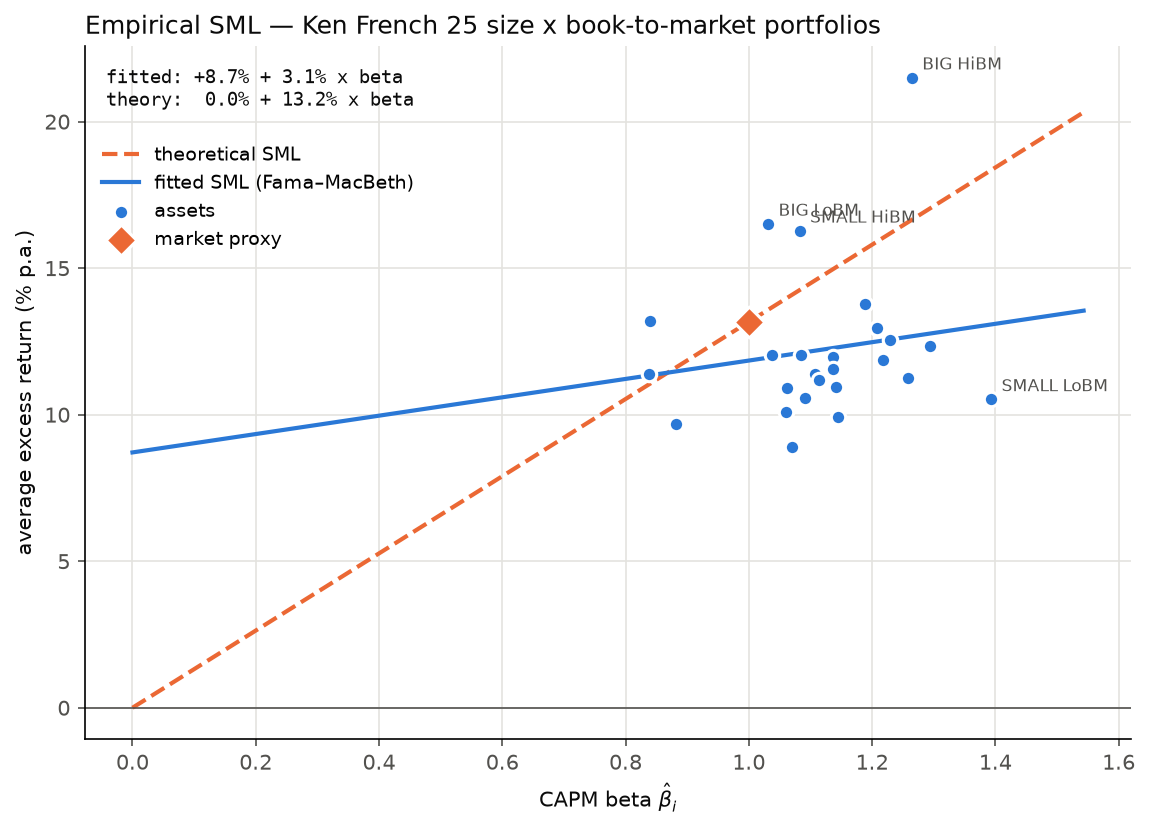

In [19]:
capm_ff25 = run_capm_analysis(
    ff25, fac25["Mkt-RF"], output_dir=OUTPUT_DIR, prefix="ff25_",
    title="Empirical SML — Ken French 25 size x book-to-market portfolios",
    labels=["SMALL LoBM", "SMALL HiBM", "BIG LoBM", "BIG HiBM"],  # the four corners
)
display(Image(filename=capm_ff25.output_paths["sml"]))

**Takeaway (2d).** On the full 30-asset universe the fitted SML has slope 18.1%
p.a. against a market premium of 13.3%, and an intercept of −0.7% — but neither
deviation is significant (t = 0.6 and −0.1). The steepness is **one stock**:
without NVDA the slope falls to 10.7% and the intercept rises to +4.5%; without
the mega-cap tech names it is 6.9% and +5.9%. The first half of the sample and
both sets of Ken French portfolios give the textbook pattern — **too flat,
intercept too high** (first half: slope 8.9% vs a 17.7% premium, intercept
+10.1%; FF 25: slope 3.1%, intercept +8.7%; momentum deciles: 1.3% and +11.4%).
The second half has a slope close to theory (9.3% vs 8.8%) but still a positive
intercept (+4.2%).
Interpretation: high-beta assets have not earned proportionally higher returns,
consistent with Black's (1972) zero-beta CAPM — borrowing-constrained investors
bid up high-beta assets (Frazzini–Pedersen's "betting against beta"). A plausible
reason our universe looks different is that it is **today's** mega-caps
backfilled: high-beta names that lost are not in it, and the one that won
spectacularly pulls the line up — survivorship working in the direction the
handout warns about. This is an interpretation, not something the data can
prove. Honest caveat: none of these slopes is statistically different from the
market premium (all |t| < 1.3), nor any intercept from zero (all |t| < 1.5);
ten years cannot settle the question, so the
**direction** is consistent across cases but the **precision** is low.

---
# Stage 3 · Factors

## (3a) Factor construction

All factors come from Kenneth French's data library (US, monthly, value-weighted
portfolios of CRSP common stocks on NYSE, AMEX and NASDAQ, NYSE breakpoints).
*Draft wording — rewrite in your own words for the report.*

* **SMB (small minus big, size).** Each June, stocks are split at the NYSE median
  market cap into small and big, and independently into three book-to-market
  groups at the NYSE 30th/70th percentiles; SMB is the average return of the
  three small portfolios minus the average of the three big ones. It captures
  the historical tendency of small firms to outperform large firms.
* **HML (high minus low, value).** From the same six portfolios: the average of
  small-value and big-value minus the average of small-growth and big-growth.
  Book equity is from the fiscal year ending in the previous calendar year,
  divided by market equity at the previous December. It captures the value
  premium — cheap stocks outperforming expensive ones.
* **Mom (momentum, also UMD).** Each month, stocks are split at the NYSE median
  size and at the 30th/70th percentiles of their prior return from month t−12
  to t−2 (skipping the most recent month, which tends to reverse); Mom is the
  average of the two winner portfolios minus the average of the two loser
  portfolios. It captures the tendency of past winners to keep winning over
  the next 3–12 months.
* **Robustness — RMW and CMA (the five-factor model).** RMW goes long robust and
  short weak operating profitability; CMA goes long conservative and short
  aggressive investment (asset growth). The FF5 file's SMB is averaged over the
  size sorts for B/M, profitability and investment, so it is kept separate from
  the FF3 SMB.

**Test assets.** Besides our 30 assets, the "better" test assets the handout
mentions: the **25 size × book-to-market portfolios** (5 × 5 NYSE-quintile sorts,
rebalanced each June) and the **10 momentum deciles** (prior 12–2 month return,
rebalanced monthly), both value-weighted.

A factor can only change an alpha through its **average return**: adding a factor
moves alpha by −(loading × factor premium). So first: what did each factor pay in
our sample?

In [20]:
ff5 = load_ff5()
premia = pd.concat(
    [
        factor_summary(fac[["Mkt-RF", "SMB", "HML", "Mom"]]),
        factor_summary(ff5.loc[excess.index, ["RMW", "CMA"]]),
    ]
)
premia.to_csv(OUTPUT_DIR / "factor_summary.csv")
display(premia.round(3))
fac[["Mkt-RF", "SMB", "HML", "Mom"]].corr().round(2)

,mean (ann.),t(mean),vol (ann.),sharpe (ann.),months
Mkt-RF,0.133,2.612,0.160,0.829,119
SMB,-0.023,-0.745,0.096,-0.237,119
HML,-0.000,-0.001,0.135,-0.000,119
Mom,0.024,0.540,0.141,0.171,119
RMW,0.025,0.886,0.090,0.281,119
CMA,-0.006,-0.215,0.087,-0.068,119


,Mkt-RF,SMB,HML,Mom
Mkt-RF,1.00,0.31,-0.02,-0.30
SMB,0.31,1.00,0.11,-0.31
HML,-0.02,0.11,1.00,-0.25
Mom,-0.30,-0.31,-0.25,1.00


**Takeaway (3a).** Over 2016–2026 **only the market paid**: 13.3% p.a. (t = 2.6).
Size earned −2.3% p.a., value exactly 0.0%, momentum +2.4%, profitability +2.5%,
investment −0.6% — none with |t| above 0.9. This decade is the well-documented
"death of value" and a small-cap drought. Consequence for Stage 3: the factors
will explain *variation* (R²) but can barely move *alphas*, because loading ×
(near-zero premium) ≈ 0.

## (3b) Alphas before versus after adding factors

The nested models: CAPM → Fama–French 3 (+SMB, HML) → Carhart 4 (+Mom). One row
per asset, one marker per model; filled markers are significant at |t| > 2.

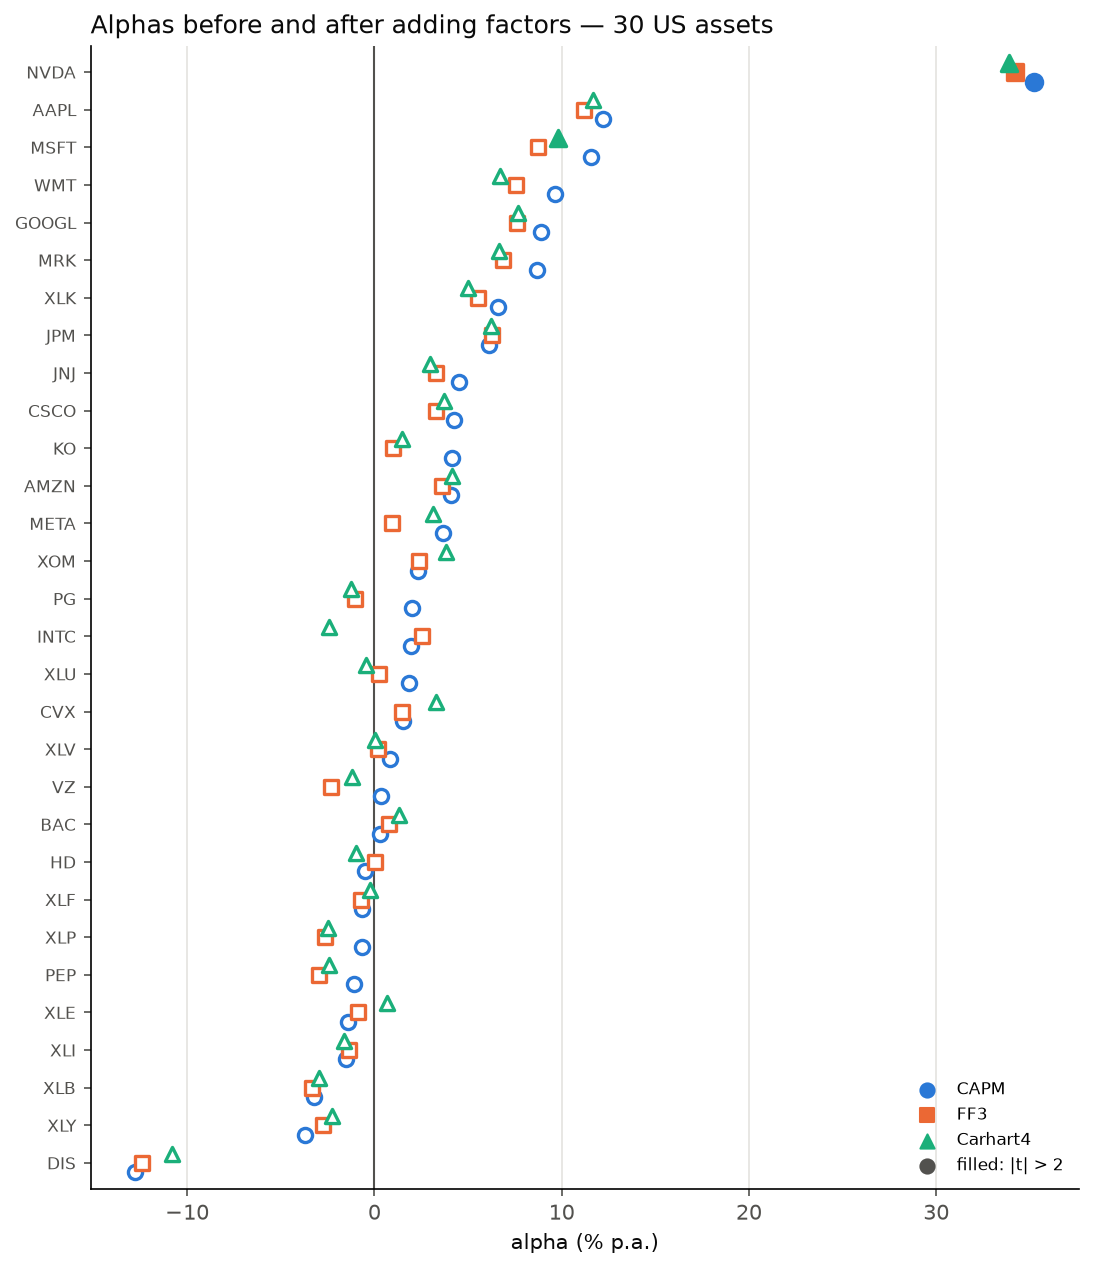

,factors,GRS,GRS p-value,mean |alpha| (ann.),max |alpha| (ann.),|t|>2,expected by chance,avg R2
model,,,,,,,,
CAPM,1.0,1.247,0.213,0.052,0.352,1.0,1.434,0.367
FF3,3.0,1.300,0.174,0.046,0.342,1.0,1.436,0.470
Carhart4,4.0,1.244,0.217,0.047,0.339,2.0,1.436,0.481


In [21]:
models = standard_models(fac, excess.index)  # CAPM, FF3, Carhart4
factors_30 = run_factor_analysis(
    excess, models, output_dir=OUTPUT_DIR,
    title="Alphas before and after adding factors — 30 US assets",
)
display(Image(filename=factors_30.output_paths["chart"]))
factors_30.summary.round(3)

In [22]:
factors_30.comparison.sort_values("CAPM alpha (ann.)", ascending=False).round(3)

,CAPM alpha (ann.),CAPM t(alpha),CAPM R2,FF3 alpha (ann.),FF3 t(alpha),FF3 R2,Carhart4 alpha (ann.),Carhart4 t(alpha),Carhart4 R2
asset,,,,,,,,,
NVDA,0.352,2.877,0.360,0.342,2.956,0.449,0.339,2.900,0.449
AAPL,0.122,1.788,0.416,0.112,1.695,0.478,0.117,1.761,0.481
MSFT,0.116,1.990,0.400,0.087,1.767,0.584,0.098,2.011,0.601
WMT,0.096,1.677,0.169,0.076,1.338,0.220,0.067,1.183,0.237
GOOGL,0.089,1.293,0.398,0.076,1.120,0.433,0.077,1.118,0.433
MRK,0.087,1.260,0.038,0.069,0.993,0.072,0.066,0.951,0.073
XLK,0.066,1.940,0.757,0.055,1.993,0.843,0.050,1.814,0.848
JPM,0.061,1.085,0.497,0.063,1.439,0.712,0.062,1.417,0.712
JNJ,0.045,0.863,0.152,0.033,0.637,0.213,0.030,0.574,0.215


**Takeaway (3b), our 30 assets.** Adding factors raises the average R² from 0.37
(CAPM) to 0.47 (FF3) and 0.48 (Carhart) but leaves alphas almost untouched: mean
|α| goes from 5.2% to 4.6–4.7% p.a. and the GRS statistic stays at 1.24–1.30
(p ≈ 0.2). The loadings below show *why*: they are large and sensible —
tech is growth (negative HML: NVDA −0.98, AMZN −0.94, MSFT −0.60), energy and
banks are value (XLE +1.13, BAC +0.95, XOM +1.03), the mega-caps are big (negative
SMB) — but they multiply premia that were ≈ 0 this decade.

In [23]:
factors_30.loadings.loc[
    ["NVDA", "MSFT", "AAPL", "AMZN", "META", "XLK", "XLE", "XOM", "BAC", "XLF", "KO", "WMT"]
].round(2)

,Mkt-RF loading,Mkt-RF t,SMB loading,SMB t,HML loading,HML t,Mom loading,Mom t,R2
asset,,,,,,,,,
NVDA,1.80,8.16,-0.22,-0.61,-0.98,-3.91,0.08,0.29,0.45
MSFT,0.96,10.46,-0.70,-4.57,-0.60,-5.77,-0.24,-2.23,0.60
AAPL,1.12,8.92,-0.28,-1.33,-0.48,-3.41,-0.11,-0.77,0.48
AMZN,1.26,9.84,-0.17,-0.82,-0.94,-6.52,-0.12,-0.81,0.59
META,1.18,6.68,-0.74,-2.53,-0.69,-3.44,-0.48,-2.33,0.39
XLK,1.21,23.15,-0.20,-2.33,-0.38,-6.44,0.12,1.91,0.85
XLE,0.95,7.94,0.05,0.27,1.13,8.34,-0.33,-2.41,0.62
XOM,0.69,5.18,-0.04,-0.18,1.03,6.85,-0.31,-2.02,0.47
BAC,1.29,14.95,0.10,0.70,0.95,9.74,-0.12,-1.21,0.78


### The sorted portfolios — where the factors were designed to work

In [24]:
ff25_models = standard_models(fac25, ff25.index)
mom10_models = standard_models(fac10, mom10.index)
factors_ff25 = run_factor_analysis(
    ff25, ff25_models, output_dir=OUTPUT_DIR, prefix="ff25_",
    title="Alphas before and after adding factors — FF 25 size x B/M",
)
factors_mom10 = run_factor_analysis(
    mom10, mom10_models, output_dir=OUTPUT_DIR, prefix="mom10_",
    title="Alphas before and after adding factors — momentum deciles",
)
sorted_summary = pd.concat(
    {"FF 25 size x B/M": factors_ff25.summary, "FF 10 momentum": factors_mom10.summary}
)
sorted_summary.to_csv(OUTPUT_DIR / "sorted_portfolios_model_summary.csv")
sorted_summary.round(3)

factors    GRS  GRS p-value  mean |alpha| (ann.)  \
                 model                                                        
FF 25 size x B/M CAPM          1.0  1.320        0.171                0.035   
                 FF3           3.0  1.223        0.242                0.017   
                 Carhart4      4.0  1.183        0.277                0.016   
FF 10 momentum   CAPM          1.0  0.917        0.520                0.028   
                 FF3           3.0  0.743        0.683                0.024   
                 Carhart4      4.0  1.031        0.423                0.019   

                           max |alpha| (ann.)  |t|>2  expected by chance  \
                 model                                                     
FF 25 size x B/M CAPM                   0.078    0.0               1.195   
                 FF3                    0.077    1.0               1.196   
                 Carhart4               0.071    1.0               1.196   
FF 10 momentum   CAPM                   0.100    0.0               0.478   
                 FF3                    0.056    0.0               0.478   
                 Carhart4               0.036    0.0               0.479   

                           avg R2  
                 model             
FF 25 size x B/M CAPM       0.693  
                 FF3        0.906  
                 Carhart4   0.907  
FF 10 momentum   CAPM       0.755  
                 FF3        0.791  
                 Carhart4   0.862

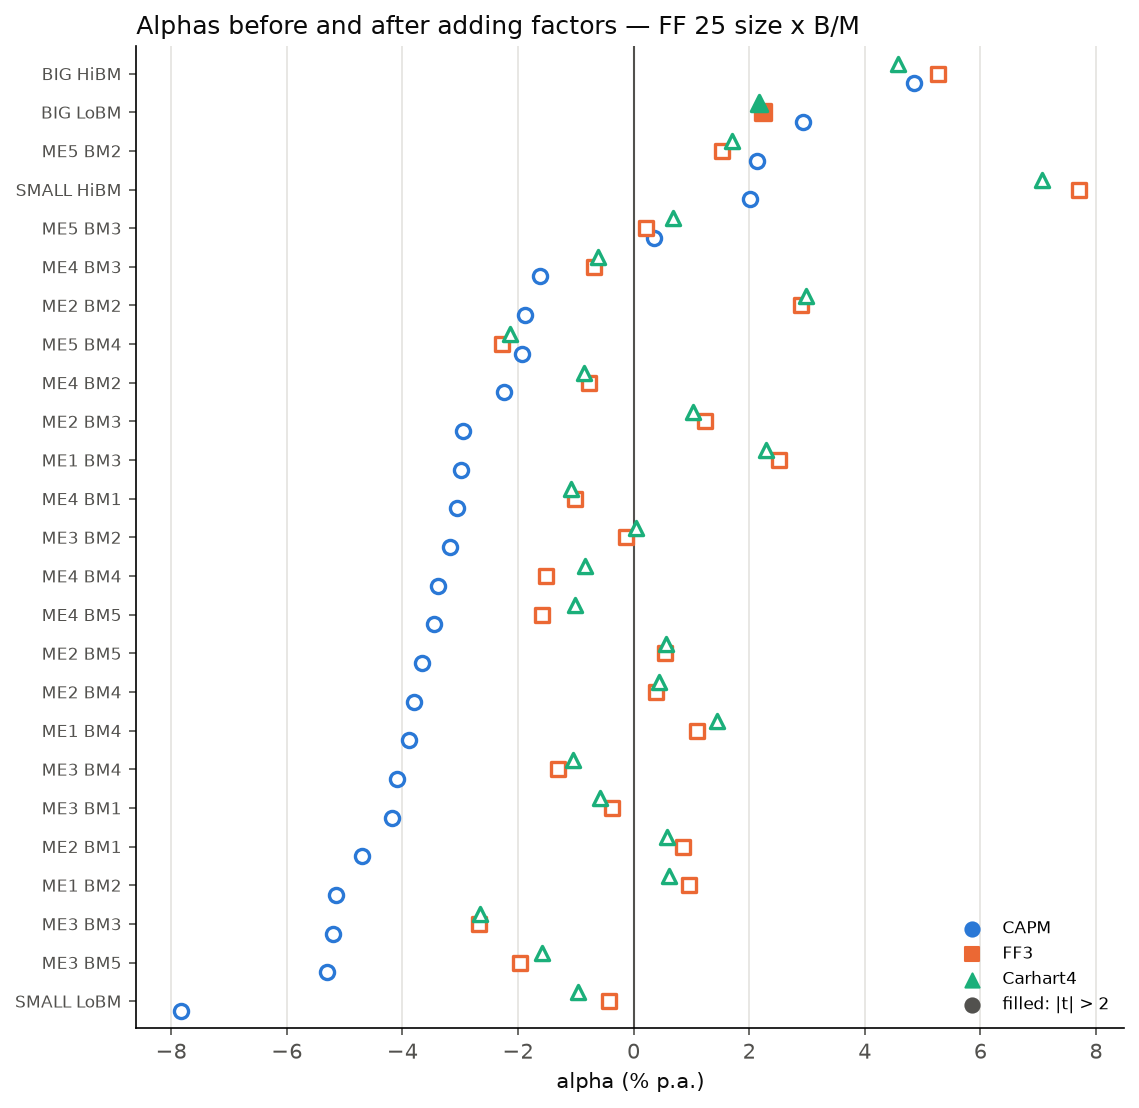

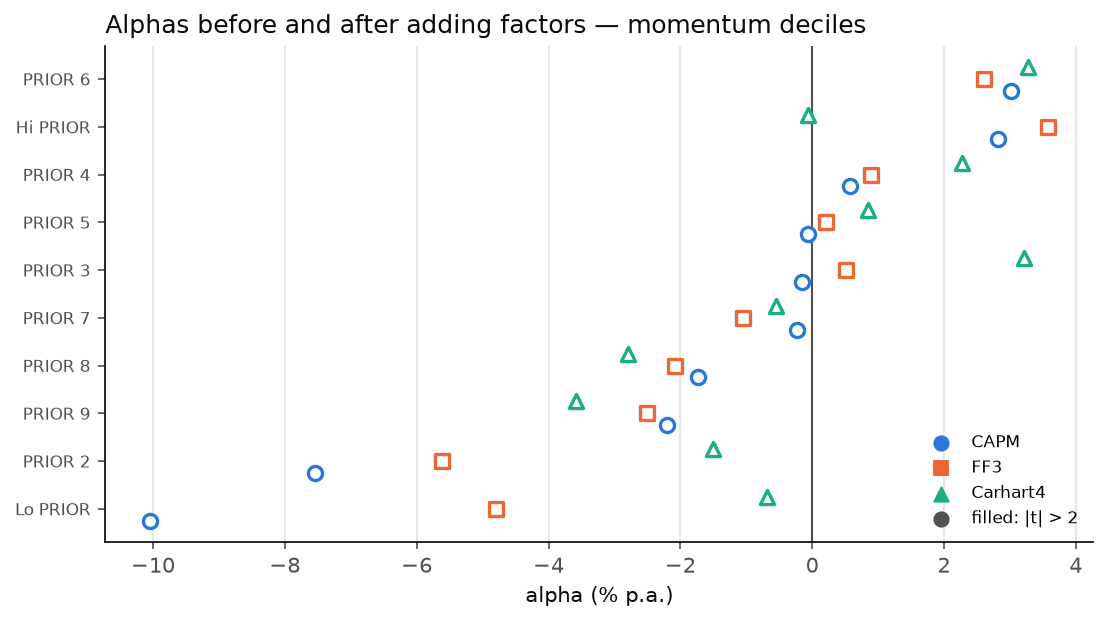

In [25]:
display(Image(filename=factors_ff25.output_paths["chart"]))
display(Image(filename=factors_mom10.output_paths["chart"]))

**Takeaway (3b), sorted portfolios.** Here the factors do their job. On the 25
size × B/M portfolios FF3 **halves** the mean |α| (3.5% → 1.7% p.a.) and lifts
R² from 0.69 to 0.91; the small-growth corner (`SMALL LoBM`, −7.8% p.a. under the
CAPM) goes to −0.4%. On the momentum deciles FF3 helps only partly, but adding
Mom shrinks the largest alpha from 10% to 3.6% p.a. (loser decile −10.0% → −0.7%)
and lifts R² from 0.79 to 0.86 — each factor absorbs the pattern it was built
for. The GRS test rejects for no model (p = 0.17–0.68), so even the CAPM's errors
on these portfolios were not significant this decade.

## (3c) Verdict: which Stage-2 anomalies do the factors absorb?

Each asset's alpha is classified as the model grows: *absorbed by* the first
model that makes it insignificant, *survives all models*, *emerges under* a
larger model (insignificant under the CAPM, significant once factor exposure is
controlled for), or *no anomaly*.

In [26]:
verdict = factors_30.verdict
display(verdict["verdict"].value_counts())
verdict[verdict["verdict"] != "no anomaly"].round(3)

verdict
no anomaly                28
emerges under Carhart4     1
survives all models        1
Name: count, dtype: int64

,CAPM alpha (ann.),t CAPM,t FF3,t Carhart4,|alpha| change CAPM->Carhart4 (ann.),verdict
asset,,,,,,
MSFT,0.116,1.990,1.767,2.011,-0.018,emerges under Carhart4
NVDA,0.352,2.877,2.956,2.900,-0.013,survives all models


In [27]:
pd.concat(
    {
        "FF 25": factors_ff25.verdict["verdict"].value_counts(),
        "FF 10 momentum": factors_mom10.verdict["verdict"].value_counts(),
    },
    axis=1,
).fillna(0).astype(int)

,FF 25,FF 10 momentum
verdict,,
no anomaly,24,10
emerges under FF3,1,0


### Robustness: the Fama–French five-factor model

In [28]:
models_ff5 = standard_models(fac, excess.index, ff5=ff5)
factors_ff5 = run_factor_analysis(
    excess, {k: models_ff5[k] for k in ["CAPM", "FF3", "FF5"]},
    output_dir=OUTPUT_DIR, prefix="ff5_",
    title="Alphas — CAPM vs FF3 vs FF5 — 30 US assets",
)
factors_ff5.summary.round(3)

,factors,GRS,GRS p-value,mean |alpha| (ann.),max |alpha| (ann.),|t|>2,expected by chance,avg R2
model,,,,,,,,
CAPM,1.0,1.247,0.213,0.052,0.352,1.0,1.434,0.367
FF3,3.0,1.300,0.174,0.046,0.342,1.0,1.436,0.470
FF5,5.0,1.289,0.183,0.047,0.336,2.0,1.437,0.515


**Takeaway (3c).** The Stage-2 anomalies split into three kinds.

1. **The single-stock anomaly survives.** NVDA's alpha (about +34% p.a., t ≈ 2.9)
   is unchanged by FF3, Carhart and FF5. It is not a hidden factor exposure —
   its growth loading would *lower* its expected return if value paid, and value
   did not pay. It is stock-specific (the AI boom) and, read with (2c), it is
   also what one extreme draw from 30 assets looks like: chance plus
   survivorship, not a priced risk. MSFT "emerging" under Carhart is a knife-edge
   (t = 1.99 → 2.01), not a finding.
2. **The portfolio-level anomalies are absorbed.** Size/value alphas are halved
   by FF3 and the momentum spread is absorbed by Mom — what Fama–French (1993)
   and Carhart (1997) designed the factors to do. The one cell that "emerges"
   (`BIG LoBM`, large growth, t = 2.2 under FF3) is within the ~1.2 per model
   that chance predicts — and large growth beating FF3's prediction is the
   mega-cap tech story again.
3. **The flat SML is only partly a factor story.** On the FF 25 portfolios FF3
   halves the CAPM's pricing errors, so part of the misfit there is size and
   value; but in our 30-asset universe the factors explain variance (R² +0.11)
   without explaining means, because 2016–2026 paid nothing for size, value or
   momentum.

Bottom line for the committee: over this decade the CAPM's failures were
**statistically weak** and the standard factors **did not earn premia**, so
multi-factor models add explanatory power for risk (useful for hedging and
attribution) but little for expected returns. The robust lessons are about
precision and selection, not about a missing factor.

## (3a, appendix) A self-built factor: momentum

The handout credits building a factor rather than downloading it. Momentum needs
only returns, so we build it from our own data with Ken French's recipe: each month,
rank assets by their return from `t−12` to `t−2` (skipping the last month, which
tends to reverse), go long the top and short the bottom with equal weights, hold
one month.

* **10 Ken French industries, 1964–2026** — industry momentum (Moskowitz and
  Grinblatt 1999): long the 3 best industries, short the 3 worst; ~750 months.
* **Our 30 assets, 2017–2026** — long the top 10, short the bottom 10; only ~107
  months, an illustration rather than a test. We do **not** use it to revise the
  Stage 3 verdict: a factor sorted from the test assets "explains" them
  mechanically.

Validation: correlation with Ken French's `Mom` (built from every CRSP stock), the
CAPM and FF3 alphas, and the cost of trading it (50 bp per unit of turnover, and
the cost at which the premium disappears).

In [29]:
from goldman.analysis import factor_report, long_short_factor, momentum_signal

industry_mom = long_short_factor(
    history.returns, momentum_signal(history.returns), n_side=3,
    name="industry momentum (10 industries)",
)
universe_returns = returns.copy()
universe_returns.index = excess.index
universe_mom = long_short_factor(
    universe_returns, momentum_signal(universe_returns), n_side=10,
    name="universe momentum (30 assets)",
)
self_built = pd.concat(
    [
        factor_report(industry_mom, history.factors_full, reference=history.momentum["Mom"]),
        factor_report(universe_mom, fac, reference=fac["Mom"]),
    ],
    axis=1,
)
self_built.to_csv(OUTPUT_DIR / "self_built_momentum.csv")
self_built

,industry momentum (10 industries),universe momentum (30 assets)
first month,1964-07,2017-10
months,746,107
mean (ann.),0.037779,0.036995
t(mean),2.184251,0.668469
sharpe (ann.),0.277028,0.223862
CAPM alpha (ann.),0.039512,0.049255
t(CAPM alpha),2.264175,0.869089
FF3 alpha (ann.),0.048614,0.03852
t(FF3 alpha),2.797028,0.681352
turnover (monthly),0.819687,0.718868


**Takeaway (3a, appendix).** Our industry momentum factor is real:
3.8% p.a. (t = 2.2) over 746 months, with alphas of 4.0% against the CAPM (t = 2.3)
and 4.9% against FF3 (t = 2.8), so it is priced beyond the market, size and value.
It correlates 0.72 with Ken French's stock-level momentum factor — the same
phenomenon at the industry level (Moskowitz and Grinblatt 1999). But it trades 82%
of its gross position every month: at 50 bp per unit of turnover the premium
becomes −1.1% p.a., and it breaks even only at about 38 bp. **A factor can be
priced and still not be worth trading.** The 30-asset version has the same 0.72
correlation with Ken French's factor, but 107 months give a mean of 3.7% p.a. with
t = 0.7 — too short to say anything, which is why the industry version carries the
evidence.

---
# Stage 4 · Judgment

The memo has to answer three questions; this section produces the evidence and
`report/draft_report.md` drafts the memo itself.

1. **Roll's critique** — redo Stage 2 with other market proxies. How much do
   betas and alphas move, and what does that imply for "testing the CAPM"?
2. **What should an investor hold** — the value-weighted index, the estimated
   tangency portfolio, or something in between? Stage 1 says the in-sample
   tangency portfolio is mostly noise; the only fair test is **out of sample**:
   rules that use only past data, judged on the months that follow.
3. **Does the answer survive** sixty years of data and a survivorship-free
   universe?

## (4a) Roll's critique in our data

Seven market proxies for the same 30 assets:

* **CRSP US market** — the Stage 2 baseline;
* **S&P 500 and MSCI World** — the handout's "local index versus MSCI World",
  measured by the total returns of the SPY and URTH ETFs (so net of their small
  fees);
* **Developed markets (Ken French)** — the library's value-weighted
  developed-markets return in USD, a fee-free check on URTH (correlation 0.996);
* **universe value-weighted** — our 30 assets at point-in-time market caps;
* **universe 1/N**;
* **ex-post tangency** — the in-sample maximum-Sharpe portfolio of the 30 assets.
  Roll's point in its purest form: with this proxy every alpha is zero *by
  construction*.

The GRS statistic is a function of Sharpe ratios only,
`GRS = (T−N−1)/N · (SR*² − SR_p²)/(1 + SR_p²)`, where `SR*` is the best Sharpe
ratio available from the assets plus the proxy: it measures how far the proxy is
from the efficient frontier. So the summary also reports both Sharpe ratios.

In [30]:
from goldman.analysis import ex_post_tangency_proxy, run_roll_analysis
from goldman.data import load_developed, load_holding_value_weights, load_index_proxy_returns

held = load_holding_value_weights(excess.index, universe=UNIVERSE, assets=excess.columns)
developed = load_developed()
index_etfs, _ = align_excess_returns(load_index_proxy_returns(), factors)
index_etfs = index_etfs.reindex(excess.index)
proxies = {
    "CRSP US market": market,
    "S&P 500 (SPY ETF)": index_etfs["S&P 500 (SPY ETF)"],
    "MSCI World (URTH ETF)": index_etfs["MSCI World (URTH ETF)"],
    "Developed markets (Ken French)": developed["Mkt-RF"].reindex(excess.index),
    "universe value-weighted": (held * excess).sum(axis=1),
    "universe 1/N": excess.mean(axis=1),
    "ex-post tangency (Roll)": ex_post_tangency_proxy(excess),
}
roll = run_roll_analysis(
    excess, proxies, output_dir=OUTPUT_DIR, highlight=["NVDA", "MSFT", "DIS"],
    chart_proxies=[
        "CRSP US market", "MSCI World (URTH ETF)", "universe value-weighted", "universe 1/N"
    ],
)
roll.summary.T.round(3)

market proxy,CRSP US market,S&P 500 (SPY ETF),MSCI World (URTH ETF),Developed markets (Ken French),universe value-weighted,universe 1/N,ex-post tangency (Roll)
proxy mean (ann.),0.133,0.133,0.113,0.109,0.185,0.151,0.649
proxy sharpe (ann.),0.833,0.866,0.761,0.730,1.078,1.038,2.403
"max sharpe, assets + proxy (ann.)",2.468,2.615,2.595,2.475,2.584,2.403,2.403
GRS,1.247,1.401,1.435,1.310,1.229,1.053,0.000
GRS p-value,0.213,0.115,0.099,0.167,0.227,0.412,1.000
mean beta,0.878,0.922,0.950,0.934,0.759,1.000,0.234
mean |beta change| vs baseline,0.000,0.043,0.073,0.062,0.163,0.123,0.645
"corr(alpha, baseline alpha)",1.000,1.000,0.994,0.992,0.901,0.990,NaN
mean |alpha| (ann.),0.052,0.049,0.057,0.060,0.042,0.055,0.000
|t(alpha)|>2,1.000,1.000,4.000,4.000,1.000,3.000,0.000


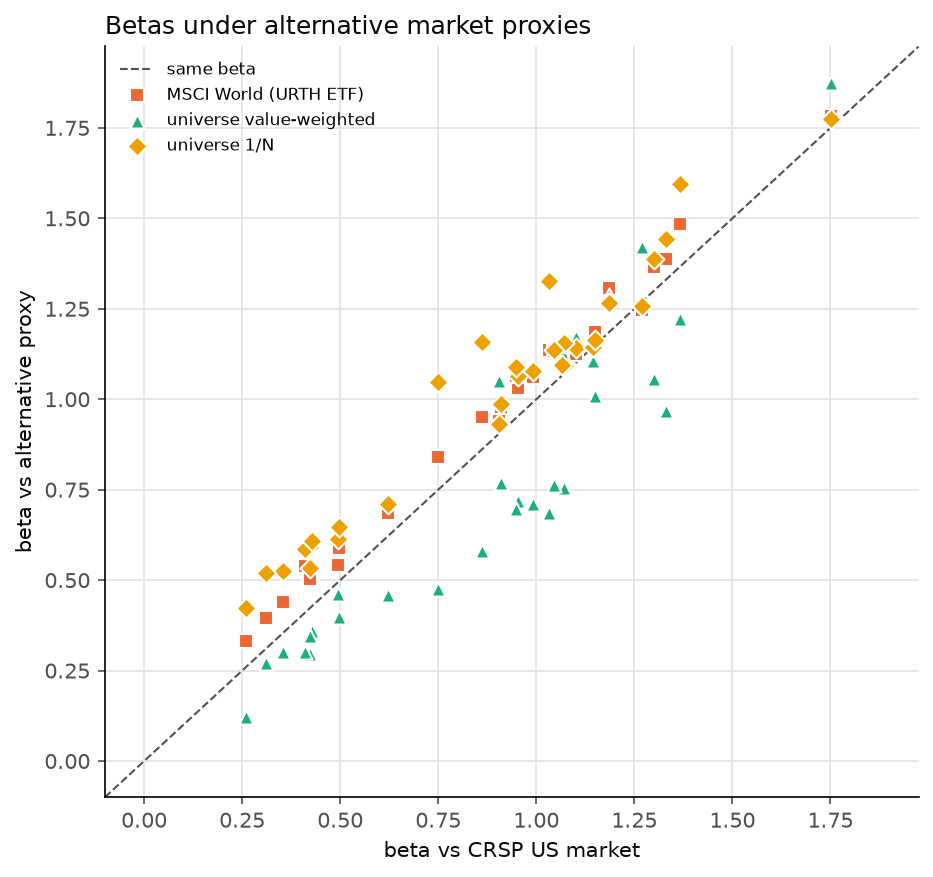

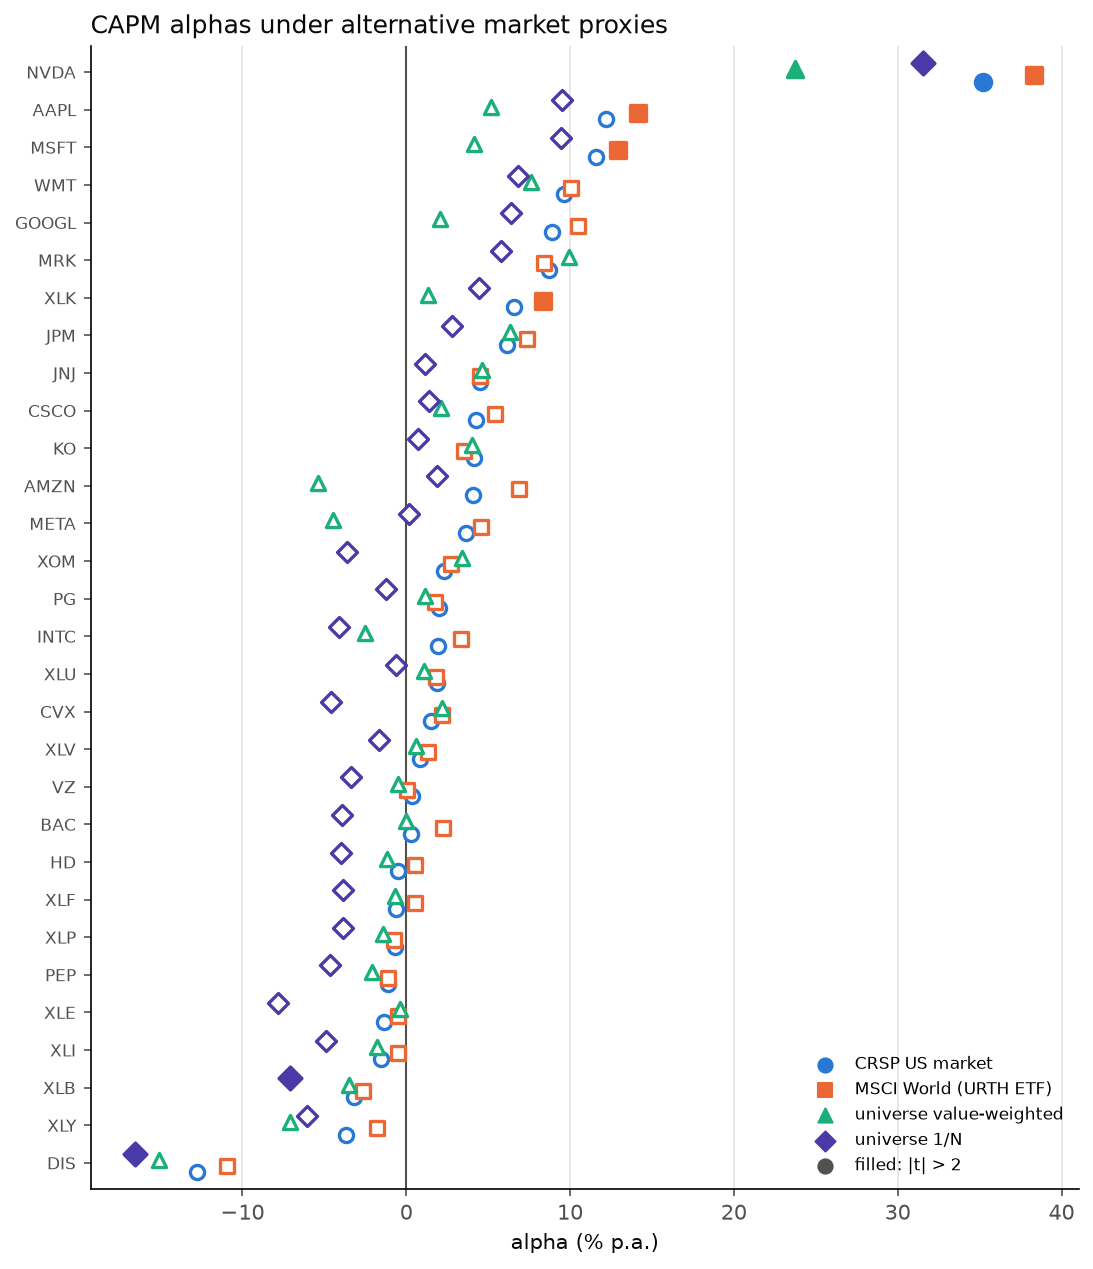

{'CRSP US market': ['NVDA'],
 'S&P 500 (SPY ETF)': ['NVDA'],
 'MSCI World (URTH ETF)': ['AAPL', 'MSFT', 'NVDA', 'XLK'],
 'Developed markets (Ken French)': ['AAPL', 'MSFT', 'NVDA', 'XLK'],
 'universe value-weighted': ['NVDA'],
 'universe 1/N': ['DIS', 'NVDA', 'XLB'],
 'ex-post tangency (Roll)': []}

In [31]:
display(Image(filename=roll.output_paths["beta_chart"]))
display(Image(filename=roll.output_paths["alpha_chart"]))
significant = {
    name: list(fit.tstats.index[fit.tstats["alpha"].abs() > 2])
    for name, fit in roll.fits.items()
}
significant

**Takeaway (4a).** **Betas move modestly, verdicts move more.** The S&P 500 is almost the CRSP
market (betas move by 0.04, the same single |t| > 2). Against MSCI World betas
rise by 0.07 on average; against the in-universe proxies they move by 0.12–0.16
(the universe value-weighted index is dominated by five tech names, so defensive
and value stocks get betas of 0.1–0.5). Alphas keep their ranking (correlation
0.90–1.00 with the baseline) but not their significance: against MSCI World
**four** assets have |t| > 2 (AAPL, MSFT, NVDA, XLK) instead of one, against 1/N
three, and NVDA's alpha ranges from +24% (universe VW) to +38–40% (MSCI World) p.a.
The joint test moves too: GRS p = 0.21 against CRSP but 0.10 against MSCI World —
the closest any proxy comes to rejecting. Whether the SML is "too steep" also
depends on the proxy: the fitted slope is 17–19% under every observable proxy, but
the theoretical slope is the proxy's own premium — 13.3% for CRSP and the S&P 500,
11.3% for MSCI World, 18.5% for the universe VW index — and against the universe
index the SML matches theory almost exactly (t = 0.1). The Ken French
developed-markets series gives the same answers as URTH, so fees and tracking are
not driving this.

**Roll's point, made exact.** With the ex-post tangency portfolio as the proxy
every alpha is zero (to 1e-17), GRS = 0 and the SML fits perfectly — the CAPM
"holds" by construction. GRS is just
(T−N−1)/N · (SR*² − SR_p²)/(1 + SR_p²): a distance between the proxy's Sharpe
ratio (0.73–1.08 here) and the best one attainable from the assets (2.4–2.6). So a
"test of the CAPM" is a test of whether the chosen proxy is mean–variance
efficient. The true market portfolio — all wealth, including bonds, property and
human capital — is unobservable, so every verdict in Stages 2–3 is conditional on
the proxy, and no proxy choice can make it unconditional.

## (4b) What should an investor hold? An out-of-sample horse race

Design (DeMiguel, Garlappi and Uppal 2009):

* every month each rule sees only the **previous 60 months**, forms weights, and
  earns the **next** month's return; rebalanced monthly; 59 out-of-sample months
  (2021-09 .. 2026-08);
* rules: value-weighted (point-in-time caps known at the end of the previous
  month), 1/N, minimum variance, plug-in tangency, long-only tangency,
  shrinkage tangency, shrinkage tangency long-only; the CRSP index is shown as an
  investable reference;
* scorecard: Sharpe ratio, the Jobson–Korkie test (Memmel correction) of equal
  Sharpe ratios against the value-weighted portfolio, drawdown, turnover
  (weights drift between rebalancing dates), and the Sharpe ratio net of a 50 bp
  cost per unit of turnover.

*Disclosure — two changes made after the first run.* (i) The first version of
the shrinkage rule took the CAPM prior's market premium from the 60-month
window. In the long sample (4c) that mean turns negative after bear markets,
which makes the prior *short* the market and the weights explode. An
equilibrium premium is positive by definition, so the rule now uses the
historical US premium known at each date (expanding mean since 1926).
(ii) Because the unconstrained shrinkage rule still failed, we **added** the
long-only shrinkage rule. Both shrinkage rules are reported; neither the
window, the cost assumption nor any other rule was changed.

**Why 60 months, not 36?** With 30 assets, a 36-month window has barely more
observations than assets, and the plug-in tangency portfolio is often not even
defined:

In [32]:
from goldman.analysis import (
    STANDARD_RULES,
    historical_premium,
    performance_table,
    plot_cumulative,
    rolling_backtest,
    tangency_sign_flips,
)

flips = pd.DataFrame(
    {
        f"{w} months": {
            "windows": len(f := tangency_sign_flips(excess, w)),
            "1'Σ⁻¹μ < 0 (tangency on the wrong side)": int((f["denominator"] < 0).sum()),
            "median gross leverage": f["gross leverage"].median(),
            "max gross leverage": f["gross leverage"].max(),
        }
        for w in (36, 60)
    }
)
flips.round(1)

,36 months,60 months
windows,84.0,60.0
1'Σ⁻¹μ < 0 (tangency on the wrong side),32.0,0.0
median gross leverage,55.4,38.5
max gross leverage,2119.4,118.9


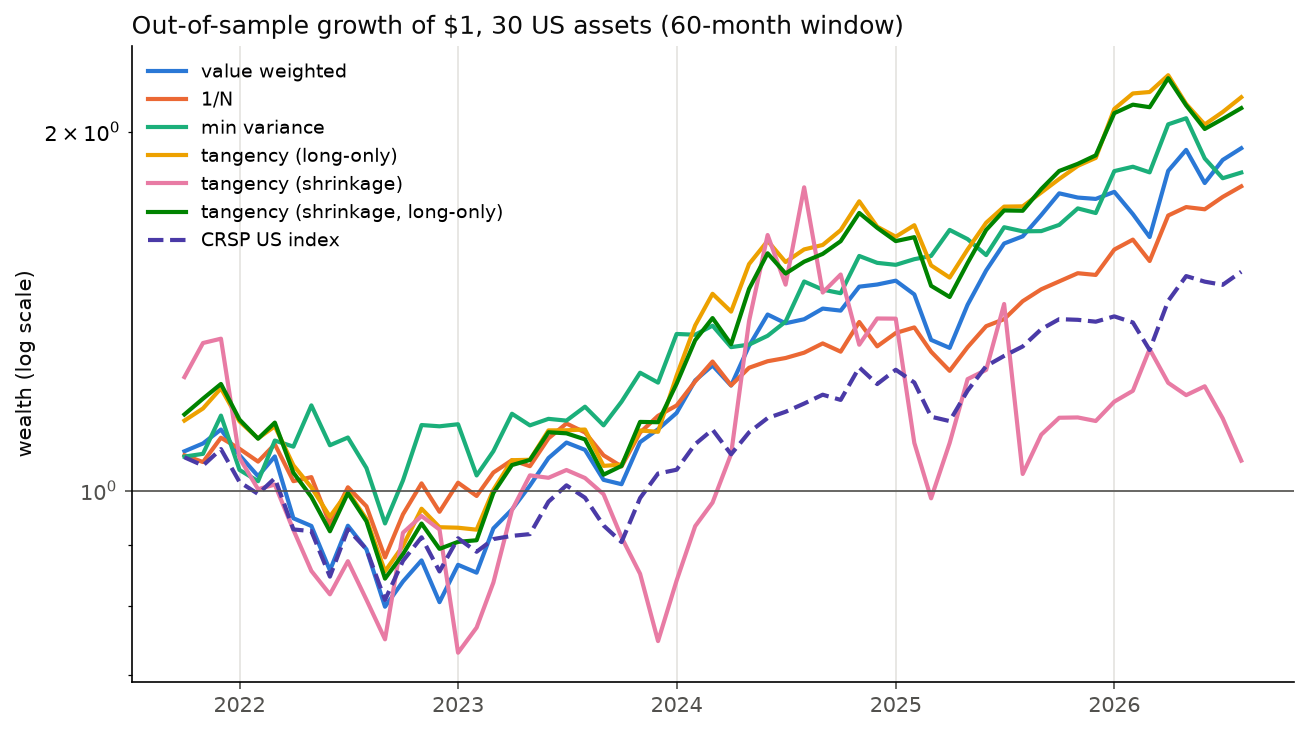

,mean (ann.),vol (ann.),sharpe (ann.),p vs value weighted,sharpe net 50bp,max drawdown,worst month,turnover (monthly),gross leverage,max |weight|,CEQ g=1 (ann.),CEQ g=5 (ann.)
rule,,,,,,,,,,,,
value weighted,0.152,0.185,0.823,1.000,0.813,-0.290,-0.113,0.026,1.000,0.184,0.135,0.067
1/N,0.131,0.146,0.897,0.762,0.877,-0.206,-0.094,0.047,1.000,0.033,0.120,0.078
min variance,0.141,0.176,0.801,0.962,0.365,-0.204,-0.101,1.308,7.487,1.219,0.125,0.064
tangency (plug-in),-0.322,1.317,-0.244,0.120,-0.671,-1.000,-1.273,129.354,44.080,6.272,-1.188,-4.655
tangency (long-only),0.171,0.179,0.954,0.690,0.895,-0.298,-0.096,0.187,1.000,0.416,0.155,0.091
tangency (shrinkage),0.092,0.401,0.228,0.260,-0.104,-0.455,-0.280,2.264,7.361,0.776,0.011,-0.311
"tangency (shrinkage, long-only)",0.169,0.190,0.887,0.806,0.824,-0.313,-0.105,0.207,1.000,0.403,0.151,0.078
CRSP US index,0.099,0.160,0.617,0.290,0.617,-0.253,-0.094,0.000,1.000,NaN,0.086,0.035


In [33]:
WINDOW = 60
premium_known = historical_premium(history.factors_full["Mkt-RF"], excess.index)
race = rolling_backtest(
    excess, STANDARD_RULES, WINDOW,
    held_market_weights=held, rf=fac["RF"], prior_premium=premium_known,
)
scorecard = performance_table(race, references={"CRSP US index": market})
scorecard.to_csv(OUTPUT_DIR / "horse_race_us30.csv")
plot_cumulative(
    race.returns.join(market.rename("CRSP US index")),
    OUTPUT_DIR / "horse_race_us30.png",
    title="Out-of-sample growth of $1, 30 US assets (60-month window)",
    exclude=["tangency (plug-in)"],
    dashed=["CRSP US index"],
)
display(Image(filename=OUTPUT_DIR / "horse_race_us30.png"))
scorecard.round(3)

**Takeaway (4b).** Over 2021-09 – 2026-08:

* **The plug-in tangency portfolio is a disaster:** Sharpe −0.24, volatility
  132% p.a., average gross leverage 44×, turnover 129× capital *per month*, and a
  −127% month that wipes the investor out.
* **Shrinking the means half-way is not enough:** unconstrained shrinkage tangency
  still runs 7× gross leverage and earns a Sharpe of 0.23 (−0.10 after costs).
  Unconstrained minimum variance looks fine gross (0.80) but trades 131% a month
  and drops to 0.37 after costs.
* **The long-only rules and 1/N are fine — and indistinguishable from the index:**
  Sharpe 0.89–0.95 against 0.82 for value-weighted, with p-values of 0.69–0.81 for
  the difference; after costs 0.82–0.90 vs 0.81.
* **Survivorship shows up directly:** the value-weighted portfolio of *our*
  universe earned an excess return of 15.2% p.a. against 9.9% for the investable
  CRSP index (Sharpe 0.82 vs 0.62). Nobody could have bought "today's mega-caps" in 2021 knowing
  they would be today's mega-caps; every rule built on this universe inherits
  that head start.

The certainty equivalents tell the same story in utility terms: for a
mean–variance investor with γ = 1 the value-weighted portfolio is worth 13.5% p.a.
risk-free, the long-only rules 15.1–15.5%, 1/N 12.0%, and the plug-in tangency
portfolio −119%.

Fifty-nine months cannot rank the sensible rules; they can only rule out the
unconstrained ones.

## (4c) Robustness: sixty years, no survivorship

Our 59 out-of-sample months are short, recent, and drawn from a universe of
today's winners. The same rules, unchanged, on the Ken French **10 industry
portfolios** (value-weighted, every CRSP stock, so no survivorship), July 1963 –
August 2026, with 60- and 120-month windows. The value-weighted rule uses each
industry's total market cap at the end of the previous month (Ken French's
number of firms × average firm size, which is measured then: these weights
reproduce the CRSP market return with a 13 bp monthly tracking error).

In [34]:
long_excess = history.returns.sub(history.factors["RF"], axis=0)
# Ken French measures month t's firm size at the end of month t-1, so these are
# already the weights a value-weighted investor holds during month t.
long_held = history.caps.div(history.caps.sum(axis=1), axis=0)
long_premium = historical_premium(history.factors_full["Mkt-RF"], long_excess.index)

long_races, long_cards = {}, {}
for w in (60, 120):
    long_races[w] = rolling_backtest(
        long_excess, STANDARD_RULES, w,
        held_market_weights=long_held, rf=history.factors["RF"], prior_premium=long_premium,
    )
    long_cards[f"{w}-month window ({long_races[w].returns.index[0]} ..)"] = performance_table(
        long_races[w], references={"CRSP US index": history.factors["Mkt-RF"]}
    )
long_scorecard = pd.concat(long_cards)
long_scorecard.to_csv(OUTPUT_DIR / "horse_race_industries_1963.csv")
long_scorecard[
    ["sharpe (ann.)", "p vs value weighted", "sharpe net 50bp", "max drawdown",
     "turnover (monthly)", "gross leverage"]
].round(3)

sharpe (ann.)  \
                              rule                                             
60-month window (1968-07 ..)  value weighted                           0.460   
                              1/N                                      0.497   
                              min variance                             0.499   
                              tangency (plug-in)                      -0.213   
                              tangency (long-only)                     0.461   
                              tangency (shrinkage)                    -0.135   
                              tangency (shrinkage, long-only)          0.474   
                              CRSP US index                            0.451   
120-month window (1973-07 ..) value weighted                           0.511   
                              1/N                                      0.551   
                              min variance                             0.575   
                              tangency (plug-in)                      -0.138   
                              tangency (long-only)                     0.455   
                              tangency (shrinkage)                     0.103   
                              tangency (shrinkage, long-only)          0.465   
                              CRSP US index                            0.505   

                                                               p vs value weighted  \
                              rule                                                   
60-month window (1968-07 ..)  value weighted                                 1.000   
                              1/N                                            0.139   
                              min variance                                   0.735   
                              tangency (plug-in)                             0.000   
                              tangency (long-only)                           0.984   
                              tangency (shrinkage)                           0.001   
                              tangency (shrinkage, long-only)                0.801   
                              CRSP US index                                  0.024   
120-month window (1973-07 ..) value weighted                                 1.000   
                              1/N                                            0.156   
                              min variance                                   0.576   
                              tangency (plug-in)                             0.000   
                              tangency (long-only)                           0.468   
                              tangency (shrinkage)                           0.009   
                              tangency (shrinkage, long-only)                0.448   
                              CRSP US index                                  0.133   

                                                               sharpe net 50bp  \
                              rule                                               
60-month window (1968-07 ..)  value weighted                             0.458   
                              1/N                                        0.488   
                              min variance                               0.351   
                              tangency (plug-in)                        -0.227   
                              tangency (long-only)                       0.364   
                              tangency (shrinkage)                      -0.143   
                              tangency (shrinkage, long-only)            0.400   
                              CRSP US index                              0.451   
120-month window (1973-07 ..) value weighted                             0.509   
                              1/N                                        0.541   
                              min variance                               0.499   
       

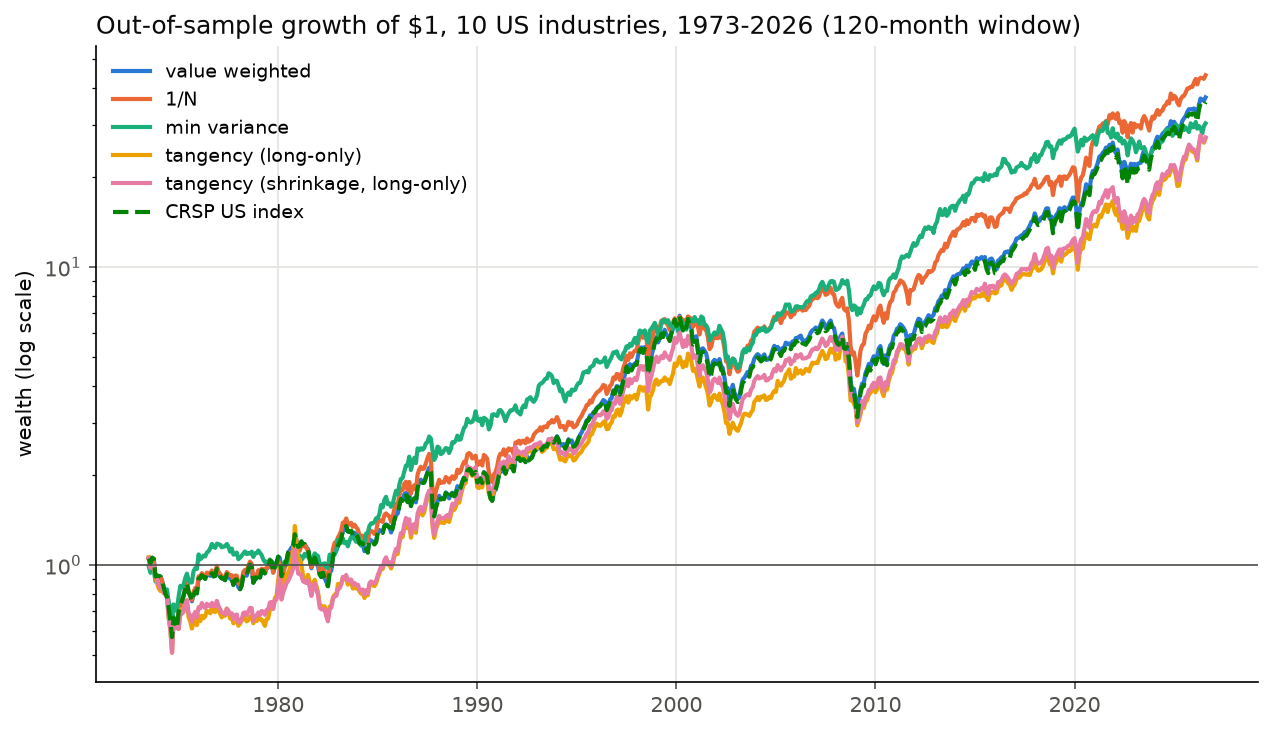

In [35]:
plot_cumulative(
    long_races[120].returns.join(history.factors["Mkt-RF"].rename("CRSP US index")),
    OUTPUT_DIR / "horse_race_industries_1963.png",
    title="Out-of-sample growth of $1, 10 US industries, 1973-2026 (120-month window)",
    exclude=["tangency (plug-in)", "tangency (shrinkage)"],
    dashed=["CRSP US index"],
)
display(Image(filename=OUTPUT_DIR / "horse_race_industries_1963.png"))

**Takeaway (4c).** Sixty years say the same thing, with power:

* **The value-weighted portfolio is the benchmark to beat** — Sharpe 0.46 (60-month
  window, 1968–2026) and 0.51 (120-month, 1973–2026), essentially the CRSP index
  (0.45 / 0.51).
* **Unconstrained optimisation fails significantly.** Plug-in tangency (Sharpe
  −0.21 / −0.14) and unconstrained shrinkage tangency (−0.14 / 0.10) are both
  *significantly worse* than the index (p ≤ 0.01) and are wiped out at some point.
* **Constraints and shrinkage make optimisation safe but not better.** Long-only
  tangency (0.46 / 0.46) and long-only shrinkage tangency (0.47 / 0.47) are
  statistically indistinguishable from the index (p = 0.45–0.98) and fall behind
  it after costs (0.36–0.42 vs 0.46–0.51), because they trade 13–26% of the
  portfolio every month against 0.5% for the index.
* **1/N and minimum variance have higher Sharpe ratios, but not significantly**
  (0.50–0.58, p = 0.14–0.74), and only 1/N also ends with more money: over the
  120-month race $1 grows to 44 (1/N), 37 (index), 30 (minimum variance) and 27
  (both long-only tangency rules), in excess-return terms. Minimum variance wins
  on risk, not return, and gives most of its edge back in costs with a 60-month
  window (0.35 net). Both edges are risk choices — equal weighting tilts toward
  smaller industries, minimum variance toward calmer ones — not information
  about expected returns.

In certainty-equivalent terms (γ = 1) the index is worth 6.0–6.8% p.a.
risk-free, the long-only optimised rules 6.1–6.3% and 1/N 6.3–7.2%. More
risk-averse investors (γ = 5) score the lower-volatility rules higher, but
two-fund separation says such an investor should hold *less of the index and more
T-bills* rather than switch to a different risky portfolio (next section).

One oddity in the table: the CRSP index shows p = 0.02 against the industries'
value-weighted portfolio in the 60-month race. The two are almost the same
portfolio (correlation 0.9996), so a 0.01 difference in Sharpe ratio becomes
"significant"; it carries no economic meaning.

This is DeMiguel, Garlappi and Uppal's (2009) result on our own code: with five
to ten years of data, the error in `μ̂` costs more than optimisation gains.


## The Mutual-Fund Theorem in practice: how much of the index?

Two-fund separation says every mean–variance investor holds the *same* risky fund
and differs only in how much of it they hold against T-bills:
`y* = premium / (γ σ²)`. With the market as the risky fund — which is what the
evidence above recommends — the split depends only on risk aversion `γ` and the
long-run equity premium. That premium is itself an estimate (its standard error
over 100 years is about 2% p.a.), so the table also shows the share at ± 2
standard errors.

In [36]:
from goldman.analysis import two_fund_allocation

allocation = two_fund_allocation(history.factors_full["Mkt-RF"])
allocation.to_csv(OUTPUT_DIR / "two_fund_allocation.csv")
print(
    f"US equity premium {allocation.attrs['premium (ann.)']:.1%} p.a. "
    f"(s.e. {allocation.attrs['premium se (ann.)']:.1%}), "
    f"volatility {allocation.attrs['vol (ann.)']:.1%}, "
    f"{allocation.attrs['months']} months since 1926-07"
)
allocation.round(2)

US equity premium 8.3% p.a. (s.e. 1.8%), volatility 18.4%, 1202 months since 1926-07


,risky share y*,y* if premium - 2se,y* if premium + 2se
risk aversion,,,
2.0,1.24,0.69,1.78
3.0,0.82,0.46,1.19
5.0,0.49,0.28,0.71
10.0,0.25,0.14,0.36


## The recommendation (summary of the memo)

**Hold the value-weighted market index, mixed with T-bills to taste.**

* **Two-fund separation, made concrete.** Every investor holds the same risky
  fund — the index — and only the split with T-bills differs. With the long-run
  US premium (8.3% ± 1.8% p.a.) and volatility (18.4%), a moderately risk-averse
  investor (γ = 3) holds about 80% in the index, a cautious one (γ = 5) about half;
  the premium's uncertainty widens these to roughly 45–120% and 30–70%.
* **Not the estimated tangency portfolio.** Its in-sample Sharpe (2.4) is noise:
  the weights correlate 0.35 between sample halves, the portfolio is often not
  even defined in short windows, and out of sample it lost everything — in our
  universe and over sixty years of industry data.
* **"Something in between" is safe but buys nothing.** With no short sales or
  shrinkage toward the CAPM it matches the index before costs and trails it
  after (60-year net Sharpe 0.36–0.42 vs 0.46–0.51), and it needs the expected
  return estimates Stages 2–3 show we do not have: alphas are jointly
  insignificant (GRS p = 0.21) and size, value and momentum earned nothing this
  decade.
* **If the committee wants to deviate,** keep the deviation small, long-only and
  shrunk toward the market, and treat 1/N or minimum-variance tilts as risk
  choices, not as sources of alpha.

The CAPM's verdict on *prices* is uncertain — Roll's critique says it always will
be — but its practical advice, *hold the market*, is the one rule that survives
every test here.

The full memo — the recommendation, Roll's critique and the result we trust
least — is drafted in `report/draft_report.md`.

---
## Deliverables and caveats

**Outputs written to `outputs/`**

| Exhibit | File |
|---|---|
| (1a) summary statistics | `summary_stats.csv` |
| (1b) tangency vs value weights | `tangency_weights.png`, `value_weights.csv` |
| (1c) subsample drift + taming | `subsample_weights.csv`, `taming_table.csv`, `taming_weights.png`, `tangency_by_subset.csv` |
| (2a) β, α, t(α), R² | `capm_table.csv` (`ff25_capm_table.csv` for the portfolios) |
| (2b) empirical SML | `sml.png`, `ff25_sml.png` |
| (2c) joint test of α = 0 | `alpha_joint_test.csv`, `alpha_joint_test_stocks.csv` |
| (2d) SML vs theory + robustness | `sml_tests.csv`, `sml_robustness.csv` |
| (3a) factor premia + self-built momentum | `factor_summary.csv`, `self_built_momentum.csv` |
| (3b) alphas before vs after factors | `alpha_comparison.png/.csv`, `model_summary.csv`, `factor_loadings.csv` (+ `ff25_`, `mom10_`, `ff5_` variants), `sorted_portfolios_model_summary.csv` |
| (3c) verdict | `anomaly_verdict.csv` (+ `ff25_`, `mom10_`, `ff5_` variants) |
| (4a) Roll's critique | `roll_summary.csv`, `roll_betas.csv/.png`, `roll_alphas.csv/.png` |
| (4b) horse race, 30 assets | `horse_race_us30.csv`, `horse_race_us30.png` |
| (4c) horse race, 10 industries 1963–2026 | `horse_race_industries_1963.csv`, `horse_race_industries_1963.png` |
| Recommendation: two-fund split | `two_fund_allocation.csv` |

**Data sources.** Yahoo adjusted closes (total-return proxy); Ken French library
for the market proxies (US and developed markets), the one-month T-bill, the
SMB/HML/Mom/RMW/CMA factors, the sorted portfolios and the 10 industry portfolios
since 1963; market caps built from point-in-time shares outstanding.

**Honest caveats to carry into the report**

- Both universes are *today's members backfilled* — survivorship bias. It
  flatters average returns, and in Stage 2 it is a plausible reason our
  30-asset SML looks steeper than the selection-free Ken French portfolios
  (the steepness rests on NVDA alone; no deviation is significant).
- Ten years of monthly data give low power: no GRS test rejects, and the SML
  slopes are never significantly different from the market premium. Report
  directions *and* their imprecision.
- The universe mixes 21 stocks with 9 sector ETFs that hold those stocks, so
  some residuals are strongly correlated (XLE–XOM 0.93, BAC–XLF 0.85,
  XLK–AAPL 0.46) even though the average pair is near zero — individual
  t-statistics are not independent tests, which is why GRS is the formal one.
- Value weights are point-in-time, but a few names (META before 2022-07, some SG
  listings) lack early Yahoo share history and carry their earliest known count
  backward.

- The horse race on our universe has only 59 out-of-sample months, all in a
  tech-led bull market, on a survivorship-biased universe; the 60-year industry
  race is the evidence the recommendation leans on.